# Reto básico 1: exploración y calidad de datos (EDA)

**III Malackathon 2026 · Mercedes-Benz Group Services Madrid · "Clustering the Star"**

Este notebook es el entregable del reto 1 definido en `Especificaciones_proyecto.md`. Incluye:

1. **Estadísticos descriptivos** de las variables principales (§5, §6).
2. **Valores nulos e inconsistencias**, con el tratamiento aplicado y justificado (§3, §4, §9, §10).
3. **Distribuciones** de las variables clave (§6–§8).
4. **Exclusión justificada** de identificadores y metadatos (§9.1).

El tratamiento de nulos parte de la decisión del equipo (`Descripcion_uso_de_datos`), con las
correcciones necesarias para que el dataset resultante sea **coherente** (§9–§10).
Las conclusiones breves están en `eda/Resumen_reto1.md`.

**Cómo ejecutarlo:** con el entorno de `requirements.txt`, ejecutar todas las celdas (Run All).
Salidas: figuras en `eda/figures/`, tablas en `eda/outputs/resultados.md` y datos tratados en CSV en
`data/processed/` (`relaciones_limpio.csv` y `clientes.csv`).

In [1]:
from __future__ import annotations

import re
from pathlib import Path

import matplotlib

try:  # dentro de Jupyter las figuras se muestran en línea; como script se guardan sin ventana
    get_ipython()  # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if IN_NOTEBOOK:
    from IPython.display import Markdown, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Rutas: funciona tanto desde la raíz del repo como desde eda/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "datos_reto_mercedes_benz_malackathon.csv").exists())
RAW = ROOT / "data" / "datos_reto_mercedes_benz_malackathon.csv"
FIG = ROOT / "eda" / "figures"
OUT = ROOT / "eda" / "outputs"
PROC = ROOT / "data" / "processed"
for p in (FIG, OUT, PROC):
    p.mkdir(parents=True, exist_ok=True)

# Fecha de referencia: la matriculación más reciente del fichero es del 2026-10-02.
REF_DATE = pd.Timestamp("2026-10-15")

STR_COLS = {c: str for c in ["client_id", "vehicle_id", "model_series", "zipcode",
                             "trip_distance_mode", "speed_mode"]}

TELEMETRY = ["trip_distance_average", "trip_distance_mode", "trip_distance_median",
             "trip_distance_all_counter", "operating_hours_total",
             "fuel_consumption_average", "speed_average", "speed_mode",
             "speed_median", "speed_all_counter"]
SOCIO = ["purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
         "population", "number_of_households", "purchasing_power_millions_eur"]
CONSENTS = ["consent_phone_communication_channel", "consent_epost_communication_channel",
            "consent_post_communication_channel"]
CLIENT_COLS = ["age_range", "gender_derived", "country_code", "months_as_mb_customer",
               "currently_connected_vehicles", "finance_leasing_status", *CONSENTS,
               "zipcode", *SOCIO]
VEHICLE_COLS = ["model_series", "vehicle_type", "model_class", "product_group",
                "engine_concept", "fuel_type", "date_of_first_registration"]
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]

# Estilo de gráficos (paleta categórica validada para daltonismo)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIV = ["#e34948", "#f0efec", "#2a78d6"]  # rojo <-> gris <-> azul

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    """Guarda la figura en eda/figures y, en el notebook, la muestra."""
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def barh(ax, s: pd.Series, fmt="{:,.0f}", color=BLUE, title=None, xlabel=None):
    """Barras horizontales finas con etiqueta de valor al final."""
    s = s[::-1]
    ax.barh(s.index.astype(str), s.values, height=0.62, color=color, edgecolor=SURFACE, linewidth=1)
    ax.grid(axis="y", visible=False)
    xmax = s.max()
    for i, v in enumerate(s.values):
        ax.text(v + xmax * 0.01, i, fmt.format(v), va="center", fontsize=7.5, color=INK2)
    ax.set_xlim(0, xmax * 1.15)
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)


def pct(x, d=1):
    return f"{100 * x:.{d}f} %"


# Las tablas se muestran en el notebook y además se acumulan en eda/outputs/resultados.md
_md: list[str] = []


def md(title: str, obj=None, floatfmt=",.2f", index=True):
    block = [f"\n### {title}\n"]
    if obj is not None:
        if isinstance(obj, pd.Series):
            obj = obj.to_frame()
        block += [obj.to_markdown(floatfmt=floatfmt, index=index), ""]
    _md.extend(block)
    if IN_NOTEBOOK:
        display(Markdown("\n".join(block)))


def note(text: str):
    _md.append(text + "\n")
    if IN_NOTEBOOK:
        display(Markdown(text))

## 1. Carga y estructura

El CSV tiene 302.850 filas y 39 columnas. `zipcode`, `model_series` y las columnas `*_mode` se leen como texto:
son códigos o listas, y con la inferencia automática `zipcode` sale con tipos mixtos porque hay CP como `A-2100`.
La primera columna (`Unnamed: 0`) es un índice de pandas exportado. No hay filas duplicadas y el par
(`client_id`, `vehicle_id`) es único.

In [2]:
# ==========================================================================
# 1. CARGA Y ESTRUCTURA
# ==========================================================================
print("Cargando datos...")
raw = pd.read_csv(RAW, dtype=STR_COLS, low_memory=False)
df = raw.copy()

md("1.1 Dimensiones")
note(f"- Filas: **{len(df):,}**  ·  Columnas: **{df.shape[1]}** (incluida la columna sin nombre `{df.columns[0]}`)")
note(f"- Clientes únicos: **{df.client_id.nunique():,}**  ·  Vehículos únicos: **{df.vehicle_id.nunique():,}**")
note(f"- Filas duplicadas completas: **{raw.drop(columns=raw.columns[0]).duplicated().sum()}**  ·  "
     f"pares (client_id, vehicle_id) duplicados: **{df.duplicated(['client_id', 'vehicle_id']).sum()}**")
unnamed = df.columns[0]
note(f"- `{unnamed}` es igual al índice posicional 0..n-1: **{(df[unnamed].astype(int) == np.arange(len(df))).all()}**")
df = df.drop(columns=unnamed)

# Tipos
dtypes = pd.DataFrame({"dtype pandas": df.dtypes.astype(str),
                       "n_unique": df.nunique(),
                       "% nulos": df.isna().mean() * 100,
                       "ejemplo": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)})
md("1.2 Tipos, cardinalidad y nulos por columna", dtypes, floatfmt=".2f")

Cargando datos...



### 1.1 Dimensiones


- Filas: **302,850**  ·  Columnas: **39** (incluida la columna sin nombre `Unnamed: 0`)

- Clientes únicos: **173,456**  ·  Vehículos únicos: **244,519**

- Filas duplicadas completas: **0**  ·  pares (client_id, vehicle_id) duplicados: **0**

- `Unnamed: 0` es igual al índice posicional 0..n-1: **True**


### 1.2 Tipos, cardinalidad y nulos por columna

|                                     | dtype pandas   |   n_unique |   % nulos | ejemplo                                                          |
|:------------------------------------|:---------------|-----------:|----------:|:-----------------------------------------------------------------|
| client_id                           | str            |     173456 |      0.00 | 000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c |
| vehicle_id                          | str            |     244519 |      0.00 | db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba668615a17eaf663d6a0 |
| age_range                           | str            |          6 |      0.00 | 35-44                                                            |
| gender_derived                      | str            |          2 |     11.20 | female                                                           |
| model_series                        | str            |         88 |      0.00 | 177                                                              |
| vehicle_type                        | str            |       1436 |      0.30 | A 180 d                                                          |
| model_class                         | str            |         42 |      1.11 | A-Class                                                          |
| product_group                       | str            |          4 |      0.00 | P                                                                |
| engine_concept                      | str            |          4 |     44.38 | COMBUSTION                                                       |
| country_code                        | str            |          2 |      0.00 | AT                                                               |
| fuel_type                           | str            |          7 |     59.02 | PETROL_PLUS                                                      |
| date_of_first_registration          | str            |       5316 |      1.38 | 2019-08-06                                                       |
| is_current_vehicle                  | bool           |          2 |      0.00 | False                                                            |
| role                                | str            |          5 |      0.00 | OWNER                                                            |
| role_type                           | str            |          2 |      0.00 | B2C                                                              |
| months_as_mb_customer               | float64        |        121 |      0.00 | 36.0                                                             |
| currently_connected_vehicles        | int64          |         22 |      0.00 | 1                                                                |
| finance_leasing_status              | str            |          4 |      0.00 | never_active                                                     |
| workshop_visits_warranty_goodwill   | int64          |         36 |      0.00 | 0                                                                |
| consent_phone_communication_channel | bool           |          2 |      0.00 | False                                                            |
| consent_epost_communication_channel | bool           |          2 |      0.00 | True                                                             |
| consent_post_communication_channel  | bool           |          2 |      0.00 | False                                                            |
| purchasing_power_per_inhabitant_eur | float64        |       5032 |      6.30 | 31518.15                                                         |
| purchasing_power_per_household_eur  | float64        |       5035 |      6.30 | 59705.4                                                          |
| population                          | float64        |       3231 |      6.28 | 104752.0                                                         |
| zipcode                             | str            |       4610 |      5.33 | 4020                                                             |
| trip_distance_average               | float64        |       5476 |     61.37 | 9.59                                                             |
| trip_distance_mode                  | str            |        108 |     59.38 | 7.5                                                              |
| trip_distance_median                | float64        |         13 |     59.38 | 7.5                                                              |
| trip_distance_all_counter           | float64        |      10780 |     59.38 | 1305.0                                                           |
| operating_hours_total               | float64        |      80943 |     57.57 | 295.98                                                           |
| fuel_consumption_average            | float64        |       2267 |     59.67 | 6.61                                                             |
| speed_average                       | float64        |       8248 |     60.22 | 40.34                                                            |
| speed_mode                          | str            |         17 |     59.82 | 30                                                               |
| speed_median                        | float64        |         12 |     59.82 | 30.0                                                             |
| speed_all_counter                   | float64        |     117441 |     59.82 | 1066745.6                                                        |
| number_of_households                | float64        |       2296 |      6.28 | 55298.0                                                          |
| purchasing_power_millions_eur       | float64        |       4973 |      6.30 | 3301.589                                                         |


## 2. Granularidad: qué es cada fila

**Cada fila es una relación cliente–vehículo, no un cliente.** Se comprueba qué atributos son constantes
por cliente y cuáles por vehículo.

In [3]:
# ==========================================================================
# 2. GRANULARIDAD
# ==========================================================================
rpc = df.groupby("client_id").size()
rpv = df.groupby("vehicle_id").size()
gran = pd.DataFrame({
    "filas por cliente": rpc.describe(percentiles=[.5, .75, .9, .95, .99, .999]),
    "filas por vehículo": rpv.describe(percentiles=[.5, .75, .9, .95, .99, .999]),
})
md("2.1 Distribución de filas por cliente y por vehículo", gran)

# Atributos constantes por cliente / vehículo
multi_c = rpc[rpc > 1].index
nu_c = df[df.client_id.isin(multi_c)].groupby("client_id")[CLIENT_COLS + ["role", "role_type"]].nunique(dropna=False)
const_c = (nu_c > 1).mean().mul(100).rename("% clientes multi-fila con >1 valor")
multi_v = rpv[rpv > 1].index
vcols = VEHICLE_COLS + ["workshop_visits_warranty_goodwill", "is_current_vehicle",
                        "operating_hours_total", "trip_distance_average", "speed_average"]
nu_v = df[df.vehicle_id.isin(multi_v)].groupby("vehicle_id")[vcols].nunique(dropna=False)
const_v = (nu_v > 1).mean().mul(100).rename("% vehículos multi-fila con >1 valor")
md("2.2 ¿Qué atributos son del cliente y cuáles de la relación?", pd.concat([const_c, const_v], axis=1), floatfmt=".2f")

heavy = pd.DataFrame({
    "umbral filas/cliente": [">10", ">20", ">50", ">100"],
    "clientes": [(rpc > t).sum() for t in (10, 20, 50, 100)],
    "filas que acumulan": [rpc[rpc > t].sum() for t in (10, 20, 50, 100)],
})
heavy["% filas"] = heavy["filas que acumulan"] / len(df) * 100
md("2.3 Clientes con muchas relaciones (posibles concesionarios, flotas, rent-a-car)", heavy, index=False, floatfmt=",.2f")
big = rpc[rpc > 20].index
hv = df[df.client_id.isin(big)]
note(f"- En clientes con >20 relaciones solo el **{pct(hv.is_current_vehicle.mean())}** de filas es vehículo actual "
     f"(vs {pct(df[~df.client_id.isin(big)].is_current_vehicle.mean())} en el resto); "
     f"rol OWNER en el {pct((hv.role == 'OWNER').mean())} de sus filas y role_type B2C en el {pct((hv.role_type == 'B2C').mean())}.")

md("2.4 role vs role_type", pd.crosstab(df.role, df.role_type, margins=True))
md("2.5 role vs is_current_vehicle", pd.crosstab(df.role, df.is_current_vehicle, margins=True))


### 2.1 Distribución de filas por cliente y por vehículo

|       |   filas por cliente |   filas por vehículo |
|:------|--------------------:|---------------------:|
| count |          173,456.00 |           244,519.00 |
| mean  |                1.75 |                 1.24 |
| std   |                5.51 |                 0.57 |
| min   |                1.00 |                 1.00 |
| 50%   |                1.00 |                 1.00 |
| 75%   |                2.00 |                 1.00 |
| 90%   |                2.00 |                 2.00 |
| 95%   |                3.00 |                 2.00 |
| 99%   |               10.00 |                 3.00 |
| 99.9% |               74.00 |                 5.00 |
| max   |              561.00 |                36.00 |



### 2.2 ¿Qué atributos son del cliente y cuáles de la relación?

|                                     |   % clientes multi-fila con >1 valor |   % vehículos multi-fila con >1 valor |
|:------------------------------------|-------------------------------------:|--------------------------------------:|
| age_range                           |                                 0.00 |                                nan    |
| gender_derived                      |                                 0.00 |                                nan    |
| country_code                        |                                 0.00 |                                nan    |
| months_as_mb_customer               |                                 0.00 |                                nan    |
| currently_connected_vehicles        |                                 0.00 |                                nan    |
| finance_leasing_status              |                                 0.00 |                                nan    |
| consent_phone_communication_channel |                                 0.00 |                                nan    |
| consent_epost_communication_channel |                                 0.00 |                                nan    |
| consent_post_communication_channel  |                                 0.00 |                                nan    |
| zipcode                             |                                 0.00 |                                nan    |
| purchasing_power_per_inhabitant_eur |                                 0.00 |                                nan    |
| purchasing_power_per_household_eur  |                                 0.00 |                                nan    |
| population                          |                                 0.00 |                                nan    |
| number_of_households                |                                 0.00 |                                nan    |
| purchasing_power_millions_eur       |                                 0.00 |                                nan    |
| role                                |                                25.99 |                                nan    |
| role_type                           |                                 1.18 |                                nan    |
| model_series                        |                               nan    |                                  0.00 |
| vehicle_type                        |                               nan    |                                  0.00 |
| model_class                         |                               nan    |                                  0.00 |
| product_group                       |                               nan    |                                  0.00 |
| engine_concept                      |                               nan    |                                  0.00 |
| fuel_type                           |                               nan    |                                  0.00 |
| date_of_first_registration          |                               nan    |                                  0.00 |
| workshop_visits_warranty_goodwill   |                               nan    |                                 62.79 |
| is_current_vehicle                  |                               nan    |                                 63.39 |
| operating_hours_total               |                               nan    |                                 56.24 |
| trip_distance_average               |                               nan    |                                 53.58 |
| speed_average                       |                               nan    |                                 53.34 |



### 2.3 Clientes con muchas relaciones (posibles concesionarios, flotas, rent-a-car)

| umbral filas/cliente   |   clientes |   filas que acumulan |   % filas |
|:-----------------------|-----------:|---------------------:|----------:|
| >10                    |       1706 |                60530 |     19.99 |
| >20                    |        833 |                47677 |     15.74 |
| >50                    |        295 |                30754 |     10.15 |
| >100                   |        102 |                17283 |      5.71 |


- En clientes con >20 relaciones solo el **10.4 %** de filas es vehículo actual (vs 68.7 % en el resto); rol OWNER en el 87.9 % de sus filas y role_type B2C en el 92.5 %.


### 2.4 role vs role_type

| role      |   B2B |    B2C |    All |
|:----------|------:|-------:|-------:|
| DRIVER    |  5521 |      0 |   5521 |
| LEGACY    |     0 |  11314 |  11314 |
| OWNER     |     0 | 264418 | 264418 |
| TEMP_USER |     0 |   3966 |   3966 |
| USER      |     0 |  17631 |  17631 |
| All       |  5521 | 297329 | 302850 |



### 2.5 role vs is_current_vehicle

| role      |   False |   True |    All |
|:----------|--------:|-------:|-------:|
| DRIVER    |    4972 |    549 |   5521 |
| LEGACY    |    6094 |   5220 |  11314 |
| OWNER     |  102782 | 161636 | 264418 |
| TEMP_USER |    3795 |    171 |   3966 |
| USER      |    5041 |  12590 |  17631 |
| All       |  122684 | 180166 | 302850 |


**Lectura:**

- Los atributos de cliente (edad, país, consentimientos, CP, socio-demografía) y los de vehículo (serie, motor,
  fecha) son **100 % consistentes** entre filas. Las visitas al taller y la telemetría varían por relación.
- 833 "clientes" tienen más de 20 relaciones. Suman el 16 % de las filas y solo el 10 % de sus vehículos es actual:
  probablemente son concesionarios, flotas o rent-a-car.
- `role_type = B2B` ⇔ `role = DRIVER` en el 100 % de los casos.

→ **El clustering debe hacerse sobre una vista agregada por cliente.**

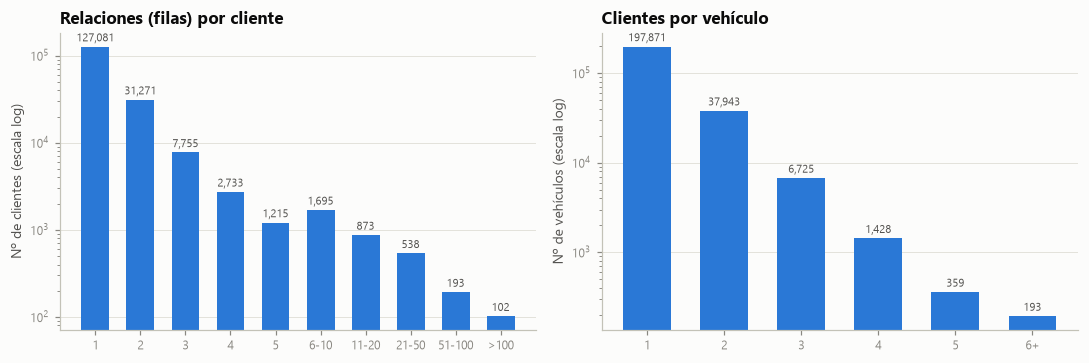

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = [1, 2, 3, 4, 5, 6, 11, 21, 51, 101, 600]
labels = ["1", "2", "3", "4", "5", "6-10", "11-20", "21-50", "51-100", ">100"]
cnt = pd.cut(rpc, bins=bins, right=False, labels=labels).value_counts().reindex(labels)
axes[0].bar(labels, cnt.values, width=0.62, color=BLUE)
axes[0].set_yscale("log")
axes[0].set_title("Relaciones (filas) por cliente")
axes[0].set_ylabel("Nº de clientes (escala log)")
axes[0].grid(axis="x", visible=False)
for i, v in enumerate(cnt.values):
    axes[0].text(i, v * 1.15, f"{v:,}", ha="center", fontsize=7, color=INK2)
cntv = rpv.clip(upper=6).value_counts().sort_index()
axes[1].bar([str(i) if i < 6 else "6+" for i in cntv.index], cntv.values, width=0.62, color=BLUE)
axes[1].set_yscale("log")
axes[1].set_title("Clientes por vehículo")
axes[1].set_ylabel("Nº de vehículos (escala log)")
axes[1].grid(axis="x", visible=False)
for i, v in enumerate(cntv.values):
    axes[1].text(i, v * 1.15, f"{v:,}", ha="center", fontsize=7, color=INK2)
save(fig, "fig01_granularidad.png")

## 3. Valores nulos

Los nulos aparecen **en bloques** (telemetría, motorización, socio-demografía). Eso apunta a que su origen está
en las fuentes de datos y no en errores de captura fila a fila.

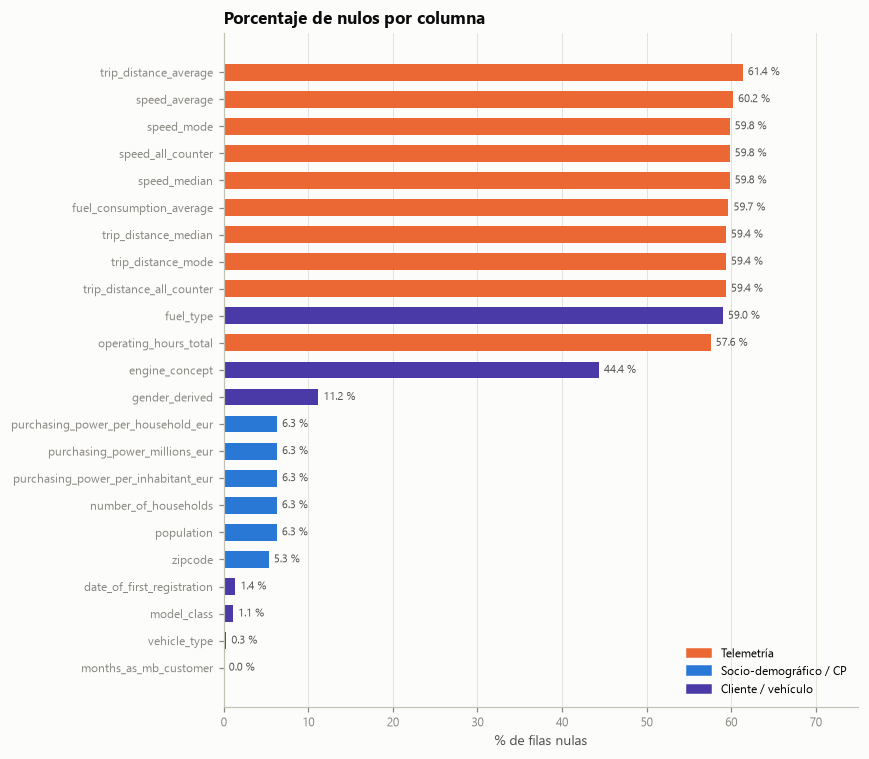

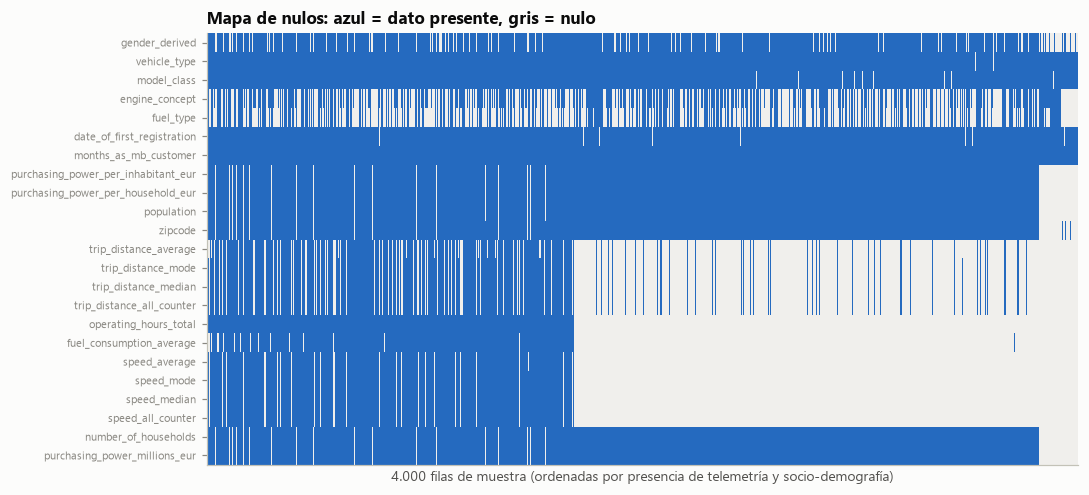

In [5]:
# ==========================================================================
# 3. VALORES NULOS
# ==========================================================================
na = df.isna().mean().sort_values(ascending=False) * 100
na = na[na > 0]
fig, ax = plt.subplots(figsize=(8, 7))
colors = [CAT[1] if c in TELEMETRY else CAT[0] if c in SOCIO + ["zipcode"] else CAT[6] for c in na.index]
s = na[::-1]
ax.barh(s.index, s.values, height=0.62, color=colors[::-1])
for i, v in enumerate(s.values):
    ax.text(v + 0.6, i, f"{v:.1f} %", va="center", fontsize=7.5, color=INK2)
ax.set_xlim(0, 75)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de filas nulas")
ax.set_title("Porcentaje de nulos por columna")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CAT[1], label="Telemetría"), Patch(color=CAT[0], label="Socio-demográfico / CP"),
                   Patch(color=CAT[6], label="Cliente / vehículo")], loc="lower right")
save(fig, "fig02_nulos_por_columna.png")

# Matriz de nulos sobre muestra ordenada
sample = df.sample(4000, random_state=42)
order_cols = [c for c in df.columns if df[c].isna().any()]
sample = sample.sort_values(["operating_hours_total", "population", "engine_concept"], na_position="last")
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.imshow(sample[order_cols].isna().T.values, aspect="auto", cmap=matplotlib.colors.ListedColormap([SEQ[4], "#f0efec"]),
          interpolation="nearest")
ax.set_yticks(range(len(order_cols)))
ax.set_yticklabels(order_cols, fontsize=7)
ax.set_xticks([])
ax.grid(False)
ax.set_xlabel("4.000 filas de muestra (ordenadas por presencia de telemetría y socio-demografía)")
ax.set_title("Mapa de nulos: azul = dato presente, gris = nulo")
save(fig, "fig03_mapa_nulos.png")

### 3.1 Telemetría: mecanismo de ausencia

El 52 % de las filas no tiene ninguna telemetría. La ausencia depende del rol, de si la relación es actual y de
la antigüedad del coche: los anteriores a 2012 casi no tienen datos y los de 2026 aún no los han acumulado. Es una
ausencia **estructural (MNAR)**: rellenarla con la media inventaría comportamiento de conducción.


### 3.1 Patrones conjuntos de nulos en el bloque de telemetría

|   patrón (1=presente) td_average/td_mode/td_median/td_all_counter/op_h/fuel/sp_average/sp_mode/sp_median/sp_all_counter |      filas |   % filas |
|------------------------------------------------------------------------------------------------------------------------:|-----------:|----------:|
|                                                                                                              0000000000 | 156,819.00 |     51.78 |
|                                                                                                              1111111111 |  96,680.00 |     31.92 |
|                                                                                                              1111000000 |  15,587.00 |      5.15 |
|                                                                                                              0000111111 |  14,151.00 |      4.67 |
|                                                                                                              0000110000 |   7,009.00 |      2.31 |
|                                                                                                              1111101111 |   4,449.00 |      1.47 |
|                                                                                                              0111111111 |   3,276.00 |      1.08 |
|                                                                                                              0111101111 |   1,113.00 |      0.37 |



### 3.2 Disponibilidad de telemetría por grupo (mecanismo de ausencia)

|                               |   % filas con alguna telemetría |
|:------------------------------|--------------------------------:|
| ('is_current_vehicle', False) |                            33.4 |
| ('is_current_vehicle', True)  |                            58.3 |
| ('role', 'DRIVER')            |                            10.1 |
| ('role', 'LEGACY')            |                            13.0 |
| ('role', 'OWNER')             |                            50.8 |
| ('role', 'TEMP_USER')         |                             3.4 |
| ('role', 'USER')              |                            54.7 |
| ('product_group', 'F')        |                             0.0 |
| ('product_group', 'G')        |                            49.2 |
| ('product_group', 'P')        |                            48.4 |
| ('product_group', 'T')        |                            48.3 |
| ('country_code', 'AT')        |                            49.4 |
| ('country_code', 'CH')        |                            47.6 |


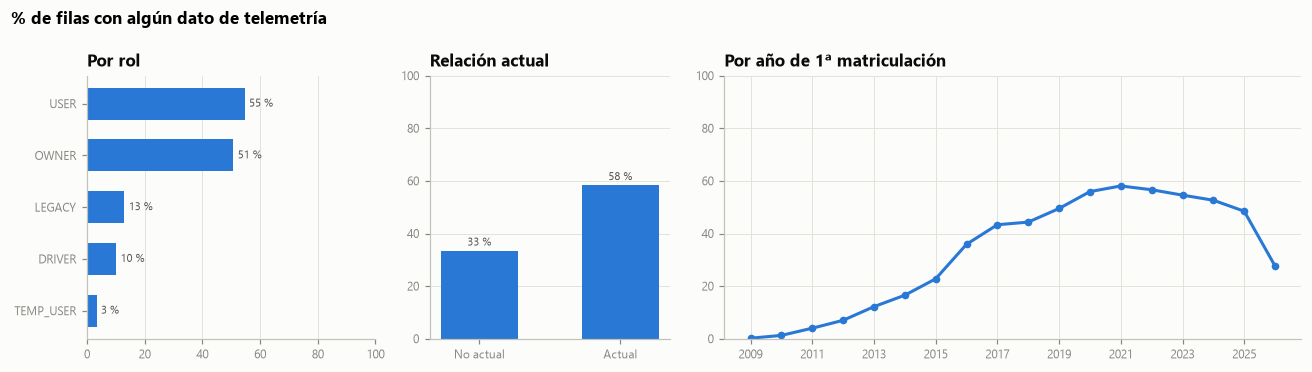

In [6]:
# Patrones del bloque de telemetría
pat = df[TELEMETRY].notna().astype(int).astype(str).agg("".join, axis=1)
patt = pat.value_counts().head(8).rename("filas").to_frame()
patt["% filas"] = patt["filas"] / len(df) * 100
patt.index.name = "patrón (1=presente) " + "/".join(c.replace("trip_distance_", "td_").replace("speed_", "sp_")
                                                   .replace("operating_hours_total", "op_h")
                                                   .replace("fuel_consumption_average", "fuel") for c in TELEMETRY)
md("3.1 Patrones conjuntos de nulos en el bloque de telemetría", patt, floatfmt=",.2f")

df["has_telemetry"] = df[TELEMETRY].notna().any(axis=1)
df["reg_date"] = pd.to_datetime(df.date_of_first_registration, errors="coerce")
df["reg_year"] = df.reg_date.dt.year

def avail(by):
    return df.groupby(by).has_telemetry.mean().mul(100)

tel_tab = pd.concat({
    "is_current_vehicle": avail("is_current_vehicle"),
    "role": avail("role"),
    "product_group": avail("product_group"),
    "country_code": avail("country_code"),
}).rename("% filas con alguna telemetría").to_frame()
md("3.2 Disponibilidad de telemetría por grupo (mecanismo de ausencia)", tel_tab, floatfmt=".1f")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.2, 1, 2.4]})
r = avail("role").sort_values()
axes[0].barh(r.index, r.values, height=0.62, color=BLUE)
axes[0].set_xlim(0, 100); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Por rol")
for i, v in enumerate(r.values):
    axes[0].text(v + 1.5, i, f"{v:.0f} %", va="center", fontsize=7.5, color=INK2)
c = avail("is_current_vehicle")
axes[1].bar(["No actual", "Actual"], c.values, width=0.55, color=BLUE)
axes[1].set_ylim(0, 100); axes[1].grid(axis="x", visible=False)
axes[1].set_title("Relación actual")
for i, v in enumerate(c.values):
    axes[1].text(i, v + 2, f"{v:.0f} %", ha="center", fontsize=7.5, color=INK2)
yy = df[df.reg_year >= 2009].groupby("reg_year").has_telemetry.mean().mul(100)
axes[2].plot(yy.index, yy.values, color=BLUE, lw=2, marker="o", ms=4)
axes[2].set_ylim(0, 100)
axes[2].set_title("Por año de 1ª matriculación")
axes[2].set_xticks(yy.index[::2])
for ax in axes:
    ax.set_ylabel("")
fig.suptitle("% de filas con algún dato de telemetría", x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "fig04_disponibilidad_telemetria.png")

### 3.2 Motorización, género y socio-demografía

- `engine_concept` (44 % nulo) y `fuel_type` (59 %) **nunca se contradicen**, y cuando falta el motor falta
  también el combustible. La ausencia depende de la antigüedad y del producto (smart: 100 %). La nomenclatura
  comercial (`EQ…`, `… e`, `… d`) permite recuperar buena parte de la información.
- El género desconocido se concentra en usuarios secundarios (TEMP_USER, USER) y en los extremos de edad:
  es un nulo **no aleatorio**.
- Socio-demografía: cada (país, CP) tiene un único valor y **ningún CP mezcla filas con y sin dato**. 993 CP
  existen en AT y en CH a la vez, así que la clave tiene que ser (país, CP).

In [7]:
# Nulos de motorización / combustible por año de matriculación
eng_year = df[df.reg_year >= 2009].groupby("reg_year").agg(
    filas=("reg_date", "size"),
    engine_na=("engine_concept", lambda s: s.isna().mean() * 100),
    fuel_na=("fuel_type", lambda s: s.isna().mean() * 100),
    telem_na=("has_telemetry", lambda s: (~s).mean() * 100))
md("3.3 Nulos de engine_concept / fuel_type / telemetría por año de matriculación (%)", eng_year, floatfmt=",.1f")

md("3.4 engine_concept vs fuel_type (filas)", pd.crosstab(df.engine_concept.fillna("<NA>"), df.fuel_type.fillna("<NA>")))

# Género por rol y edad
md("3.5 gender_derived por rol (% columna)",
   pd.crosstab(df.gender_derived.fillna("<NA>"), df.role, normalize="columns").mul(100), floatfmt=".1f")

# Socio-demográficos
note("**Socio-demográficos y CP:**")
zip_nosoc = df.zipcode.notna() & df.population.isna()
note(f"- Filas sin CP: **{df.zipcode.isna().sum():,}**; con CP pero sin cruce socio-demográfico: **{zip_nosoc.sum():,}**; "
     f"con CP y población pero sin poder adquisitivo: **{(df.population.notna() & df.purchasing_power_per_inhabitant_eur.isna()).sum():,}** "
     f"(todas con population = 0).")
z = df.zipcode.dropna()
note(f"- CP con formato no estándar (no 4 dígitos): **{(~z.str.fullmatch(r'\d{4}')).sum()}** → "
     f"{sorted(z[~z.str.fullmatch(r'\d{4}')].unique().tolist())}")
note(f"- CP que existen en AT y en CH a la vez: **{len(set(df[df.country_code == 'AT'].zipcode.dropna()) & set(df[df.country_code == 'CH'].zipcode.dropna())):,}** "
     "→ el CP solo identifica una zona junto con `country_code`.")
note(f"- (country, CP) con más de un valor socio-demográfico: **{(df.dropna(subset=['zipcode']).groupby(['country_code', 'zipcode']).population.nunique() > 1).sum()}**")
md("3.6 % nulos por país", df.groupby("country_code")[["gender_derived", "zipcode", "population",
                                                       "purchasing_power_per_inhabitant_eur", "engine_concept",
                                                       "fuel_type", "has_telemetry"]]
   .agg(lambda s: (s.isna() if s.name != "has_telemetry" else ~s).mean() * 100), floatfmt=".2f")


### 3.3 Nulos de engine_concept / fuel_type / telemetría por año de matriculación (%)

|   reg_year |    filas |   engine_na |   fuel_na |   telem_na |
|-----------:|---------:|------------:|----------:|-----------:|
|    2,009.0 |    493.0 |       100.0 |     100.0 |       99.8 |
|    2,010.0 |    710.0 |        99.7 |     100.0 |       98.7 |
|    2,011.0 |  1,074.0 |        96.6 |      99.2 |       96.0 |
|    2,012.0 |  1,614.0 |        84.4 |      89.7 |       93.0 |
|    2,013.0 |  2,182.0 |        66.4 |      76.1 |       87.8 |
|    2,014.0 |  3,173.0 |        44.4 |      76.5 |       83.5 |
|    2,015.0 |  5,376.0 |        29.7 |      74.1 |       77.2 |
|    2,016.0 |  9,501.0 |        27.3 |      71.8 |       64.1 |
|    2,017.0 | 14,956.0 |        24.3 |      72.2 |       56.7 |
|    2,018.0 | 19,183.0 |        41.9 |      73.0 |       55.7 |
|    2,019.0 | 26,700.0 |        51.5 |      67.4 |       50.5 |
|    2,020.0 | 29,449.0 |        48.4 |      58.0 |       44.1 |
|    2,021.0 | 33,606.0 |        51.0 |      61.1 |       41.9 |
|    2,022.0 | 33,531.0 |        50.6 |      59.7 |       43.4 |
|    2,023.0 | 35,910.0 |        45.4 |      54.8 |       45.4 |
|    2,024.0 | 34,625.0 |        40.5 |      48.3 |       47.4 |
|    2,025.0 | 28,417.0 |        38.9 |      46.6 |       51.5 |
|    2,026.0 | 18,135.0 |        30.6 |      37.0 |       72.4 |



### 3.4 engine_concept vs fuel_type (filas)

| engine_concept   |   <NA> |   DIESEL |   DIESEL,ELECTRIC |   ELECTRIC |   PETROL |   PETROL,ELECTRIC |   PETROL_PLUS |   PETROL_PLUS,ELECTRIC |
|:-----------------|-------:|---------:|------------------:|-----------:|---------:|------------------:|--------------:|-----------------------:|
| <NA>             | 134390 |        0 |                 0 |          0 |        0 |                 0 |             0 |                      0 |
| COMBUSTION       |  43915 |    28475 |                 0 |          0 |    14422 |                 0 |         11612 |                      0 |
| ELECTRIC         |      0 |        0 |                 0 |      20944 |        0 |                 0 |             0 |                      0 |
| MILD_HYBRID      |     29 |     7418 |                 0 |          0 |    17946 |                 0 |          2362 |                      0 |
| PLUGIN_HYBRID    |    411 |        0 |              8604 |          0 |        0 |              7371 |             0 |                   4951 |



### 3.5 gender_derived por rol (% columna)

| gender_derived   |   DRIVER |   LEGACY |   OWNER |   TEMP_USER |   USER |
|:-----------------|---------:|---------:|--------:|------------:|-------:|
| <NA>             |      4.1 |     11.9 |     9.2 |        38.1 |   36.2 |
| female           |      4.7 |      9.8 |    15.0 |         8.8 |   24.6 |
| male             |     91.2 |     78.3 |    75.7 |        53.1 |   39.2 |


**Socio-demográficos y CP:**

- Filas sin CP: **16,135**; con CP pero sin cruce socio-demográfico: **2,879**; con CP y población pero sin poder adquisitivo: **73** (todas con population = 0).

- CP con formato no estándar (no 4 dígitos): **5** → ['55605', 'A-2100', 'CH-6340', 'Ottenbach']

- CP que existen en AT y en CH a la vez: **993** → el CP solo identifica una zona junto con `country_code`.

- (country, CP) con más de un valor socio-demográfico: **0**


### 3.6 % nulos por país

| country_code   |   gender_derived |   zipcode |   population |   purchasing_power_per_inhabitant_eur |   engine_concept |   fuel_type |   has_telemetry |
|:---------------|-----------------:|----------:|-------------:|--------------------------------------:|-----------------:|------------:|----------------:|
| AT             |            13.42 |      6.85 |         8.30 |                                  8.33 |            43.55 |       56.65 |           50.63 |
| CH             |             9.94 |      4.46 |         5.13 |                                  5.15 |            44.84 |       60.37 |           52.44 |


## 4. Inconsistencias y anomalías

Se buscan relaciones deterministas (columnas que son copia de otras), taxonomías solapadas, valores imposibles
y artefactos.

In [8]:
# ==========================================================================
# 4. INCONSISTENCIAS Y ANOMALÍAS
# ==========================================================================
# 4.1 Redundancias exactas
s = df.dropna(subset=["population", "purchasing_power_per_inhabitant_eur"]).query("population > 0 and number_of_households > 0")
err1 = ((s.purchasing_power_per_inhabitant_eur * s.population / 1e6 - s.purchasing_power_millions_eur).abs()
        / s.purchasing_power_millions_eur)
err2 = ((s.purchasing_power_millions_eur * 1e6 / s.number_of_households - s.purchasing_power_per_household_eur).abs()
        / s.purchasing_power_per_household_eur)
note("**Redundancias deterministas:**")
note(f"- `purchasing_power_millions_eur` = `purchasing_power_per_inhabitant_eur` × `population` / 1e6 → error relativo máx. **{err1.max():.1e}**")
note(f"- `purchasing_power_per_household_eur` = `purchasing_power_millions_eur` × 1e6 / `number_of_households` → error relativo máx. **{err2.max():.1e}**")
hh = s.population / s.number_of_households
note(f"- Tamaño medio del hogar (population / households): mediana **{hh.median():.2f}**, p1–p99 [{hh.quantile(.01):.2f}, {hh.quantile(.99):.2f}]")
note(f"- `role_type` = B2B ⇔ `role` = DRIVER en el **100 %** de filas (ver 2.4).")
ms_conf = (df.dropna(subset=["model_class"]).groupby("model_series").model_class.nunique() > 1).sum()
note(f"- `model_series` → `model_class` es una función: series con >1 clase = **{ms_conf}**.")

**Redundancias deterministas:**

- `purchasing_power_millions_eur` = `purchasing_power_per_inhabitant_eur` × `population` / 1e6 → error relativo máx. **7.4e-04**

- `purchasing_power_per_household_eur` = `purchasing_power_millions_eur` × 1e6 / `number_of_households` → error relativo máx. **7.4e-04**

- Tamaño medio del hogar (population / households): mediana **2.24**, p1–p99 [1.85, 2.76]

- `role_type` = B2B ⇔ `role` = DRIVER en el **100 %** de filas (ver 2.4).

- `model_series` → `model_class` es una función: series con >1 clase = **0**.

**Redundancias encontradas:** PA total = PA/hab × población / 1e6 y PA/hogar = PA total / hogares (error < 0,1 %);
población ↔ hogares (ρ = 0,998); `model_series` → `model_class` es una función exacta.

A continuación: taxonomía de `model_class` (etiquetas solapadas de distintas épocas y series nuevas de 2026 sin clase),
fechas y antigüedad como cliente.

In [9]:
# 4.2 Taxonomía de model_class
mc = df.model_class.value_counts(dropna=False)
md("4.1 model_class (filas) - taxonomía solapada", mc.rename("filas"))
mc_na = df[df.model_class.isna()].groupby("model_series").agg(
    filas=("vehicle_id", "size"),
    vehicle_types=("vehicle_type", lambda s: ", ".join(s.value_counts().head(3).index)),
    año_mediano=("reg_year", "median"))
md("4.2 model_class nulo: series de modelo nuevas sin clase asignada", mc_na.sort_values("filas", ascending=False), floatfmt=",.0f")
md("4.3 product_group vs nº de clases", df.groupby("product_group").agg(
    filas=("vehicle_id", "size"), clases=("model_class", lambda s: ", ".join(s.value_counts().head(5).index))))

# 4.3 vehicle_type con códigos técnicos (vans)
vt = df.vehicle_type.dropna()
tech = vt[vt.str.contains(r"\dX\d|\s{2,}")]
note(f"- `vehicle_type` con códigos técnicos (furgonetas, p. ej. `{tech.value_counts().index[0]}`): **{len(tech):,}** filas, "
     f"{tech.nunique()} valores distintos. Cardinalidad total: **{vt.nunique():,}** valores.")

# 4.4 Fechas
note("**Fechas de primera matriculación:**")
note(f"- Rango: **{df.reg_date.min().date()}** → **{df.reg_date.max().date()}**; nulas: **{df.reg_date.isna().sum():,}**; "
     f"posteriores a la fecha de referencia ({REF_DATE.date()}): **{(df.reg_date > REF_DATE).sum()}**; anteriores a 2009: **{(df.reg_year < 2009).sum()}**")
df["vehicle_age_years"] = (REF_DATE - df.reg_date).dt.days / 365.25

# 4.5 months_as_mb_customer
cl0 = df.drop_duplicates("client_id")
months = cl0.months_as_mb_customer
vc_m = months.value_counts()
note("**`months_as_mb_customer` (a nivel cliente):**")
note(f"- Valor 36: **{vc_m.get(36.0, 0):,}** clientes ({pct(vc_m.get(36.0, 0) / len(cl0))}) frente a "
     f"{vc_m.get(35.0, 0):,} en 35 y {vc_m.get(37.0, 0):,} en 37 → pico artificial (≈ ×{vc_m.get(36.0, 0) / np.mean([vc_m.get(35.0, 0), vc_m.get(37.0, 0)]):.0f}).")
note(f"- Valor 0: **{vc_m.get(0.0, 0):,}** clientes; máximo **{months.max():.0f}** meses (10 años, posible truncado); nulos: **{months.isna().sum()}**.")
first_reg = df.groupby("client_id").reg_date.min()
m36 = cl0.set_index("client_id").months_as_mb_customer
diff = m36 - (REF_DATE - first_reg).dt.days / 30.44
note(f"- `months_as_mb_customer` − meses desde la matriculación más antigua del cliente: mediana **{diff.median():.1f}** "
     f"(p5 {diff.quantile(.05):.0f}, p95 {diff.quantile(.95):.0f}). La relación con la marca empieza en la *conexión* "
     "(Mercedes me), no en la matriculación: lo normal es que sea más corta que la edad del coche (vehículos de ocasión, "
     "conexión posterior). Los clientes con 36 meses tienen su primer coche matriculado sobre todo en "
     f"{', '.join(map(str, first_reg[m36[m36 == 36].index].dt.year.value_counts().head(3).index.astype(int)))}.")

# currently_connected_vehicles vs filas actuales
ncur = df.groupby("client_id").is_current_vehicle.sum()
ccv = cl0.set_index("client_id").currently_connected_vehicles
note(f"- `currently_connected_vehicles` = nº de filas con `is_current_vehicle` = True del cliente en el **{pct((ccv == ncur[ccv.index]).mean(), 3)}** "
     f"de clientes (discrepancias: {(ccv != ncur[ccv.index]).sum()}). Clientes sin ningún vehículo actual: **{(ncur == 0).sum():,}** ({pct((ncur == 0).mean())}).")


### 4.1 model_class (filas) - taxonomía solapada

| model_class             |   filas |
|:------------------------|--------:|
| GLC-Class               |   44198 |
| C-Class                 |   34990 |
| A-Class                 |   32524 |
| B-/GLA-/GLB-Class       |   28497 |
| V-Class / Vito          |   27349 |
| E-Class                 |   21171 |
| GLE-/GLS-Class          |   19170 |
| CLA-Class               |   15791 |
| EQA-/EQB-Class          |   11559 |
| Sprinter                |   10466 |
| EQE-Class               |    4947 |
| S-Class                 |    4892 |
| GLA-Class               |    4760 |
| G-Class                 |    4373 |
| EQC-Class               |    4059 |
| Citan                   |    3477 |
| E-Class Coupé/Cabriolet |    3397 |
| nan                     |    3369 |
| M-/GL-/GLE-/GLS-Class   |    3138 |
| B-Class                 |    3135 |
| EQS-Class               |    2331 |
| CLS-Class               |    2191 |
| CLE-Class               |    2187 |
| A-Class/CLA-Class       |    2113 |
| AMG GT                  |    1355 |
| SL-Class                |    1313 |
| GLE-Class               |    1184 |
| AMG GT 4-Door           |    1038 |
| fortwo / forfour        |     936 |
| SLK-/SLC-Class          |     788 |
| S-Class Coupé/Cabriolet |     656 |
| X-Class                 |     442 |
| M-/GL-Class             |     269 |
| SLK-Class               |     212 |
| Viano/Vito              |     202 |
| SLS AMG                 |     130 |
| CLK-Class               |      85 |
| R-Class                 |      61 |
| AMG ONE                 |      41 |
| CL-Class                |      36 |
| M-Class                 |      12 |
| SLR McLaren             |       3 |
| Maybach                 |       3 |



### 4.2 model_class nulo: series de modelo nuevas sin clase asignada

|   model_series |   filas | vehicle_types                           |   año_mediano |
|---------------:|--------:|:----------------------------------------|--------------:|
|            540 |    1645 | GLC 400 4MATIC, GLC 250                 |         2,026 |
|            244 |     955 | GLB 350 4MATIC, GLB 250+, GLB 200+      |         2,026 |
|            178 |     489 | CLA 220 4MATIC, CLA 200 4MATIC, CLA 180 |         2,026 |
|            248 |     206 | GLB 220 4MATIC, GLB 200 4MATIC, GLB 200 |         2,026 |
|            520 |      73 | C 400 4MATIC electric                   |         2,026 |
|            449 |       1 | 300  VLE  4X2   3342                    |           nan |



### 4.3 product_group vs nº de clases

| product_group   |   filas | clases                                                  |
|:----------------|--------:|:--------------------------------------------------------|
| F               |     936 | fortwo / forfour                                        |
| G               |    4373 | G-Class                                                 |
| P               |  255604 | GLC-Class, C-Class, A-Class, B-/GLA-/GLB-Class, E-Class |
| T               |   41937 | V-Class / Vito, Sprinter, Citan, X-Class, Viano/Vito    |


- `vehicle_type` con códigos técnicos (furgonetas, p. ej. `V 300AVG/L4X2   3200`): **41,059** filas, 660 valores distintos. Cardinalidad total: **1,436** valores.

**Fechas de primera matriculación:**

...

**`months_as_mb_customer` (a nivel cliente):**

- Valor 36: **21,179** clientes (12.2 %) frente a 2,619 en 35 y 2,770 en 37 → pico artificial (≈ ×8).

- Valor 0: **7,254** clientes; máximo **120** meses (10 años, posible truncado); nulos: **2**.

- `months_as_mb_customer` − meses desde la matriculación más antigua del cliente: mediana **-27.2** (p5 -102, p95 -1). La relación con la marca empieza en la *conexión* (Mercedes me), no en la matriculación: lo normal es que sea más corta que la edad del coche (vehículos de ocasión, conexión posterior). Los clientes con 36 meses tienen su primer coche matriculado sobre todo en 2019, 2020, 2018.

- `currently_connected_vehicles` = nº de filas con `is_current_vehicle` = True del cliente en el **99.998 %** de clientes (discrepancias: 4). Clientes sin ningún vehículo actual: **18,048** (10.4 %).

**Lectura de lo anterior:**

- `months_as_mb_customer` tiene un **pico artificial en 36 meses**: el 12 % de los clientes, 8 veces más que los
  meses vecinos. Su máximo es exactamente 120.
- `currently_connected_vehicles` cuadra con `is_current_vehicle` en el 99,998 % de los clientes. El 10,4 % de los
  clientes no tiene ningún vehículo actual.

### 4.1 Telemetría: valores imposibles y artefactos

Hay velocidades medias por debajo de 1 km/h, horas a 0, contadores a 0 con métricas informadas y valores en los
topes del sensor. Las medianas y modas son marcas de clase de **dos esquemas de bins distintos**, y las modas son
texto con empates.

In [10]:
# 4.6 Telemetría: anomalías
anom = pd.DataFrame({
    "regla": [
        "speed_average < 1 km/h",
        "speed_average ≥ 150 km/h",
        "operating_hours_total = 0",
        "operating_hours_total > 5.000 h",
        "trip_distance_all_counter = 0 con mediana/moda informada",
        "speed_all_counter = 0",
        "fuel_consumption_average en tope inferior (3,0)",
        "fuel_consumption_average en tope superior (50,0)",
        "trip_distance_average en tope (300 km)",
        "fuel_consumption_average informado en ELECTRIC",
        "trip_distance_mode con varios valores (empate)",
        "speed_mode con varios valores (empate)",
    ],
    "filas": [
        (df.speed_average < 1).sum(),
        (df.speed_average >= 150).sum(),
        (df.operating_hours_total == 0).sum(),
        (df.operating_hours_total > 5000).sum(),
        ((df.trip_distance_all_counter == 0) & df.trip_distance_median.notna()).sum(),
        (df.speed_all_counter == 0).sum(),
        (df.fuel_consumption_average == 3.0).sum(),
        (df.fuel_consumption_average == 50.0).sum(),
        (df.trip_distance_average == 300.0).sum(),
        ((df.engine_concept == "ELECTRIC") & df.fuel_consumption_average.notna()).sum(),
        df.trip_distance_mode.str.contains(",", na=False).sum(),
        df.speed_mode.str.contains(",", na=False).sum(),
    ]})
md("4.4 Anomalías detectadas en telemetría", anom, index=False, floatfmt=",.0f")
note(f"- Valores únicos de `trip_distance_median`: {sorted(df.trip_distance_median.dropna().unique().tolist())}")
note(f"- Valores únicos de `speed_median`: {[round(x, 4) for x in sorted(df.speed_median.dropna().unique().tolist())]}")
note("- Son marcas de clase de histogramas: conviven **dos esquemas de bins** (1/3/7,5/15/27,5/42,5… y 2,5/10/22,5…), "
     "probablemente por distintas generaciones de la unidad telemática. `speed_median` incluye el artefacto de coma flotante 220.00000000000003.")
md("4.5 Consumo medio por fuel_type (l/100 km)", df.groupby(df.fuel_type.fillna("<NA>")).fuel_consumption_average.describe(), floatfmt=",.2f")


### 4.4 Anomalías detectadas en telemetría

| regla                                                    |   filas |
|:---------------------------------------------------------|--------:|
| speed_average < 1 km/h                                   |     889 |
| speed_average ≥ 150 km/h                                 |      26 |
| operating_hours_total = 0                                |     140 |
| operating_hours_total > 5.000 h                          |     427 |
| trip_distance_all_counter = 0 con mediana/moda informada |    6027 |
| speed_all_counter = 0                                    |    1223 |
| fuel_consumption_average en tope inferior (3,0)          |      20 |
| fuel_consumption_average en tope superior (50,0)         |       8 |
| trip_distance_average en tope (300 km)                   |      34 |
| fuel_consumption_average informado en ELECTRIC           |       0 |
| trip_distance_mode con varios valores (empate)           |    7049 |
| speed_mode con varios valores (empate)                   |    1223 |


- Valores únicos de `trip_distance_median`: [1.0, 2.5, 3.0, 7.5, 10.0, 15.0, 22.5, 27.5, 42.5, 62.5, 87.5, 150.0, 300.0]

- Valores únicos de `speed_median`: [0.125, 10.0625, 15.0625, 30.0, 40.0, 45.0, 50.0, 75.0, 110.0, 150.0, 165.0, 220.0]

- Son marcas de clase de histogramas: conviven **dos esquemas de bins** (1/3/7,5/15/27,5/42,5… y 2,5/10/22,5…), probablemente por distintas generaciones de la unidad telemática. `speed_median` incluye el artefacto de coma flotante 220.00000000000003.


### 4.5 Consumo medio por fuel_type (l/100 km)

| fuel_type            |     count |   mean |    std |    min |    25% |    50% |    75% |    max |
|:---------------------|----------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|
| <NA>                 | 74,244.00 |   8.63 |   3.02 |   3.00 |   6.82 |   8.25 |   9.73 |  50.00 |
| DIESEL               | 18,465.00 |   7.65 |   2.94 |   3.00 |   5.94 |   6.75 |   8.86 |  50.00 |
| DIESEL,ELECTRIC      |  3,575.00 |   5.65 |   2.11 |   3.00 |   4.22 |   5.29 |   6.72 |  48.25 |
| ELECTRIC             |      0.00 | nan    | nan    | nan    | nan    | nan    | nan    | nan    |
| PETROL               | 14,187.00 |   8.91 |   2.99 |   3.00 |   7.38 |   8.34 |   9.51 |  50.00 |
| PETROL,ELECTRIC      |  3,077.00 |   6.24 |   2.48 |   3.00 |   4.47 |   5.93 |   7.63 |  38.25 |
| PETROL_PLUS          |  6,546.00 |  12.48 |   3.96 |   5.23 |   9.87 |  11.42 |  14.28 |  46.71 |
| PETROL_PLUS,ELECTRIC |  2,031.00 |   7.93 |   4.11 |   3.00 |   4.89 |   7.09 |   9.96 |  42.61 |


## 5. Estadísticos descriptivos

A nivel fila (relación). Las variables de uso y de tamaño de zona tienen colas largas (asimetría de 3 a 8), así que
K-Means necesitará transformación logarítmica o winsorización antes de escalar. `currently_connected_vehicles`
sale inflado a nivel fila por los clientes con muchas filas: la media es 2,15 por fila frente a 1,04 por cliente.

In [11]:
# ==========================================================================
# 5. ESTADÍSTICOS DESCRIPTIVOS
# ==========================================================================
num_cols = ["months_as_mb_customer", "currently_connected_vehicles", "workshop_visits_warranty_goodwill",
            "vehicle_age_years", *SOCIO, "trip_distance_average", "trip_distance_median", "trip_distance_all_counter",
            "operating_hours_total", "fuel_consumption_average", "speed_average", "speed_median", "speed_all_counter"]
desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[num_cols].skew()
desc["% nulos"] = df[num_cols].isna().mean() * 100
md("5.1 Estadísticos descriptivos numéricos (nivel fila cliente-vehículo)", desc, floatfmt=",.2f")

# IQR outliers
iqr = {}
for c in num_cols:
    x = df[c].dropna()
    q1, q3 = x.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr[c] = {"límite inf.": lo, "límite sup.": hi, "% outliers (IQR)": ((x < lo) | (x > hi)).mean() * 100}
md("5.2 Outliers por regla IQR (1,5×)", pd.DataFrame(iqr).T, floatfmt=",.2f")

cat_cols = ["age_range", "gender_derived", "country_code", "product_group", "model_class", "engine_concept",
            "fuel_type", "role", "role_type", "finance_leasing_status", "is_current_vehicle", *CONSENTS]
cat_desc = pd.DataFrame({
    "n_unique": df[cat_cols].nunique(),
    "moda": df[cat_cols].mode().iloc[0],
    "% moda": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols],
    "% nulos": df[cat_cols].isna().mean() * 100})
md("5.3 Descriptivos categóricos (nivel fila)", cat_desc, floatfmt=".2f")


### 5.1 Estadísticos descriptivos numéricos (nivel fila cliente-vehículo)

|                                     |      count |         mean |          std |       min |        1% |        25% |          50% |          75% |           99% |              max |   skew |   % nulos |
|:------------------------------------|-----------:|-------------:|-------------:|----------:|----------:|-----------:|-------------:|-------------:|--------------:|-----------------:|-------:|----------:|
| months_as_mb_customer               | 302,846.00 |        43.87 |        26.89 |      0.00 |      0.00 |      25.00 |        39.00 |        60.00 |        115.00 |           120.00 |   0.60 |      0.00 |
| currently_connected_vehicles        | 302,850.00 |         2.15 |         3.53 |      0.00 |      0.00 |       1.00 |         1.00 |         2.00 |         19.00 |            21.00 |   3.46 |      0.00 |
| workshop_visits_warranty_goodwill   | 302,850.00 |         1.75 |         2.43 |      0.00 |      0.00 |       0.00 |         1.00 |         3.00 |         10.00 |            44.00 |   2.19 |      0.00 |
| vehicle_age_years                   | 298,668.00 |         5.09 |         3.19 |      0.04 |      0.16 |       2.57 |         4.74 |         7.13 |         14.37 |            39.75 |   0.71 |      1.38 |
| purchasing_power_per_inhabitant_eur | 283,763.00 |    46,481.17 |    17,294.53 | 19,701.53 | 24,291.65 |  31,518.15 |    46,165.64 |    54,210.68 |    106,183.57 |       148,353.74 |   1.74 |      6.30 |
| purchasing_power_per_household_eur  | 283,763.00 |   104,766.27 |    41,597.55 | 45,087.34 | 51,698.89 |  71,961.82 |   102,246.51 |   122,300.85 |    246,174.02 |       342,497.95 |   1.73 |      6.30 |
| population                          | 283,836.00 |    19,664.85 |    36,803.22 |      0.00 |    470.00 |   3,135.00 |     7,132.00 |    17,625.00 |    220,313.00 |       220,794.00 |   3.65 |      6.28 |
| number_of_households                | 283,836.00 |     9,336.42 |    17,781.94 |      0.00 |    209.00 |   1,344.00 |     3,145.00 |     8,353.00 |    102,026.00 |       102,998.00 |   3.49 |      6.28 |
| purchasing_power_millions_eur       | 283,763.00 |       733.17 |     1,042.27 |      0.65 |     20.48 |     139.21 |       329.27 |       873.42 |      5,324.88 |         5,998.91 |   2.81 |      6.30 |
| trip_distance_average               | 116,993.00 |        16.16 |        10.67 |      1.00 |      2.84 |      10.15 |        14.02 |        19.53 |         49.39 |           300.00 |   7.62 |     61.37 |
| trip_distance_median                | 123,020.00 |         6.62 |         7.77 |      1.00 |      1.00 |       3.00 |         7.50 |         7.50 |         27.50 |           300.00 |  19.16 |     59.38 |
| trip_distance_all_counter           | 123,020.00 |     2,351.70 |     2,768.20 |      0.00 |      0.00 |     518.00 |     1,593.00 |     3,321.00 |     11,404.62 |        89,078.00 |   4.94 |     59.38 |
| operating_hours_total               | 128,492.00 |       620.27 |       742.61 |      0.00 |      0.09 |     137.48 |       406.51 |       855.95 |      3,393.64 |        26,842.00 |   4.06 |     57.57 |
| fuel_consumption_average            | 122,125.00 |         8.56 |         3.26 |      3.00 |      3.59 |       6.58 |         8.11 |         9.72 |         19.00 |            50.00 |   3.60 |     59.67 |
| speed_average                       | 120,468.00 |        48.67 |        14.21 |      0.12 |      2.29 |      41.23 |        49.34 |        57.25 |         80.45 |           220.00 |  -0.30 |     60.22 |
| speed_median                        | 121,691.00 |        42.63 |        17.41 |      0.12 |      0.12 |      30.00 |        50.00 |        50.00 |         75.00 |           220.00 |   0.13 |     59.82 |
| speed_all_counter                   | 121,691.00 | 2,530,486.84 | 7,269,688.37 |      0.00 |      0.00 | 628,505.80 | 1,698,968.30 | 3,382,487.15 | 13,326,747.63 | 1,452,478,022.80 | 145.80 |     59.82 |



### 5.2 Outliers por regla IQR (1,5×)

|                                     |   límite inf. |   límite sup. |   % outliers (IQR) |
|:------------------------------------|--------------:|--------------:|-------------------:|
| months_as_mb_customer               |        -27.50 |        112.50 |               1.50 |
| currently_connected_vehicles        |         -0.50 |          3.50 |              11.03 |
| workshop_visits_warranty_goodwill   |         -4.50 |          7.50 |               3.39 |
| vehicle_age_years                   |         -4.27 |         13.96 |               1.22 |
| purchasing_power_per_inhabitant_eur |     -2,520.64 |     88,249.48 |               2.71 |
| purchasing_power_per_household_eur  |     -3,546.74 |    197,809.40 |               3.59 |
| population                          |    -18,600.00 |     39,360.00 |               9.76 |
| number_of_households                |     -9,169.50 |     18,866.50 |              10.42 |
| purchasing_power_millions_eur       |       -962.10 |      1,974.72 |               8.16 |
| trip_distance_average               |         -3.92 |         33.60 |               4.67 |
| trip_distance_median                |         -3.75 |         14.25 |              13.54 |
| trip_distance_all_counter           |     -3,686.50 |      7,525.50 |               4.14 |
| operating_hours_total               |       -940.22 |      1,933.65 |               4.64 |
| fuel_consumption_average            |          1.87 |         14.43 |               3.75 |
| speed_average                       |         17.20 |         81.28 |               3.74 |
| speed_median                        |          0.00 |         80.00 |               0.43 |
| speed_all_counter                   | -3,502,466.23 |  7,513,459.18 |               4.64 |



### 5.3 Descriptivos categóricos (nivel fila)

|                                     |   n_unique | moda         |   % moda |   % nulos |
|:------------------------------------|-----------:|:-------------|---------:|----------:|
| age_range                           |          6 | 45-54        |    22.54 |      0.00 |
| gender_derived                      |          2 | male         |    82.96 |     11.20 |
| country_code                        |          2 | CH           |    63.69 |      0.00 |
| product_group                       |          4 | P            |    84.40 |      0.00 |
| model_class                         |         42 | GLC-Class    |    14.76 |      1.11 |
| engine_concept                      |          4 | COMBUSTION   |    58.43 |     44.38 |
| fuel_type                           |          7 | DIESEL       |    28.92 |     59.02 |
| role                                |          5 | OWNER        |    87.31 |      0.00 |
| role_type                           |          2 | B2C          |    98.18 |      0.00 |
| finance_leasing_status              |          4 | never_active |    58.28 |      0.00 |
| is_current_vehicle                  |          2 | True         |    59.49 |      0.00 |
| consent_phone_communication_channel |          2 | True         |    85.64 |      0.00 |
| consent_epost_communication_channel |          2 | True         |    98.32 |      0.00 |
| consent_post_communication_channel  |          2 | True         |    85.13 |      0.00 |


## 6. Perfil del cliente (una fila por cliente, n = 173.456)

In [12]:
# ==========================================================================
# 6. VISTA A NIVEL CLIENTE
# ==========================================================================
g = df.groupby("client_id")
cl = cl0.set_index("client_id")[CLIENT_COLS].copy()
cl["n_relaciones"] = g.size()
cl["n_vehiculos_actuales"] = g.is_current_vehicle.sum()
cl["es_b2b"] = g.role_type.apply(lambda s: (s == "B2B").any())
cur = df[df.is_current_vehicle]
cl["edad_media_vehiculo_actual"] = cur.groupby("client_id").vehicle_age_years.mean()
cl["tiene_electrificado_actual"] = cur.groupby("client_id").engine_concept.apply(
    lambda s: s.isin(["ELECTRIC", "PLUGIN_HYBRID"]).any()).reindex(cl.index)
cl["visitas_taller_total"] = g.workshop_visits_warranty_goodwill.sum()
cl["tiene_telemetria"] = g.has_telemetry.any()

clv = {}
for c in ["age_range", "gender_derived", "country_code", "finance_leasing_status"]:
    t = cl[c].fillna("<NA>").value_counts()
    clv[c] = pd.DataFrame({"clientes": t, "%": t / len(cl) * 100})
md("6.1 Perfil demográfico y comercial (nivel cliente)",
   pd.concat(clv, names=["variable", "valor"]), floatfmt=",.2f")

cc = cl[CONSENTS].astype(int).astype(str).agg("".join, axis=1).value_counts()
cct = pd.DataFrame({"clientes": cc, "%": cc / len(cl) * 100})
cct.index.name = "teléfono/email/correo (1=sí)"
md("6.2 Combinaciones de consentimiento (nivel cliente)", cct, floatfmt=",.2f")
md("6.3 Tasa de consentimiento por canal y país (%)", cl.groupby("country_code")[CONSENTS].mean() * 100, floatfmt=".1f")

cln = cl[["months_as_mb_customer", "currently_connected_vehicles", "n_relaciones", "visitas_taller_total",
          "edad_media_vehiculo_actual", "purchasing_power_per_inhabitant_eur"]].describe(
    percentiles=[.25, .5, .75, .9, .99]).T
md("6.4 Descriptivos numéricos a nivel cliente", cln, floatfmt=",.2f")

md("6.5 Edad × financiación (% fila)", pd.crosstab(cl.age_range, cl.finance_leasing_status, normalize="index")
   .reindex(AGE_ORDER).mul(100), floatfmt=".1f")
md("6.6 País × financiación (% fila)", pd.crosstab(cl.country_code, cl.finance_leasing_status, normalize="index").mul(100), floatfmt=".1f")
md("6.7 Edad × género (% columna)", pd.crosstab(cl.gender_derived.fillna("<NA>"), cl.age_range, normalize="columns")[AGE_ORDER].mul(100), floatfmt=".1f")
md("6.8 Poder adquisitivo por habitante (mediana €) por país y edad",
   cl.pivot_table(index="age_range", columns="country_code", values="purchasing_power_per_inhabitant_eur", aggfunc="median").reindex(AGE_ORDER),
   floatfmt=",.0f")
note(f"- Clientes con algún vehículo electrificado (BEV/PHEV) actual: **{pct(cl.tiene_electrificado_actual.fillna(False).mean())}**; "
     f"clientes multi-vehículo (≥2 actuales): **{pct((cl.n_vehiculos_actuales >= 2).mean())}**; B2B: **{pct(cl.es_b2b.mean(), 2)}**.")


### 6.1 Perfil demográfico y comercial (nivel cliente)

|                                                  |   clientes |     % |
|:-------------------------------------------------|-----------:|------:|
| ('age_range', '45-54')                           |  36,439.00 | 21.01 |
| ('age_range', '65+')                             |  35,057.00 | 20.21 |
| ('age_range', '55-64')                           |  34,007.00 | 19.61 |
| ('age_range', '35-44')                           |  32,747.00 | 18.88 |
| ('age_range', '25-34')                           |  26,970.00 | 15.55 |
| ('age_range', '<25')                             |   8,236.00 |  4.75 |
| ('gender_derived', 'male')                       | 112,726.00 | 64.99 |
| ('gender_derived', 'female')                     |  31,332.00 | 18.06 |
| ('gender_derived', '<NA>')                       |  29,398.00 | 16.95 |
| ('country_code', 'CH')                           | 114,763.00 | 66.16 |
| ('country_code', 'AT')                           |  58,693.00 | 33.84 |
| ('finance_leasing_status', 'never_active')       | 122,401.00 | 70.57 |
| ('finance_leasing_status', 'active_FL_only')     |  41,173.00 | 23.74 |
| ('finance_leasing_status', 'was_active')         |   5,646.00 |  3.26 |
| ('finance_leasing_status', 'active_FL_and_CASH') |   4,236.00 |  2.44 |



### 6.2 Combinaciones de consentimiento (nivel cliente)

|   teléfono/email/correo (1=sí) |   clientes |     % |
|-------------------------------:|-----------:|------:|
|                            111 | 140,639.00 | 81.08 |
|                            010 |  17,442.00 | 10.06 |
|                            110 |   7,149.00 |  4.12 |
|                            011 |   5,256.00 |  3.03 |
|                            001 |   1,471.00 |  0.85 |
|                            100 |   1,011.00 |  0.58 |
|                            101 |     488.00 |  0.28 |



### 6.3 Tasa de consentimiento por canal y país (%)

| country_code   |   consent_phone_communication_channel |   consent_epost_communication_channel |   consent_post_communication_channel |
|:---------------|--------------------------------------:|--------------------------------------:|-------------------------------------:|
| AT             |                                  84.9 |                                  98.0 |                                 85.8 |
| CH             |                                  86.7 |                                  98.4 |                                 85.0 |



### 6.4 Descriptivos numéricos a nivel cliente

|                                     |      count |      mean |       std |       min |       25% |       50% |       75% |       90% |        99% |        max |
|:------------------------------------|-----------:|----------:|----------:|----------:|----------:|----------:|----------:|----------:|-----------:|-----------:|
| months_as_mb_customer               | 173,454.00 |     33.90 |     20.73 |      0.00 |     18.00 |     36.00 |     47.00 |     62.00 |      91.00 |     120.00 |
| currently_connected_vehicles        | 173,456.00 |      1.04 |      0.88 |      0.00 |      1.00 |      1.00 |      1.00 |      1.00 |       3.00 |      21.00 |
| n_relaciones                        | 173,456.00 |      1.75 |      5.51 |      1.00 |      1.00 |      1.00 |      2.00 |      2.00 |      10.00 |     561.00 |
| visitas_taller_total                | 173,456.00 |      3.06 |      4.70 |      0.00 |      0.00 |      2.00 |      4.00 |      7.00 |      18.00 |     206.00 |
| edad_media_vehiculo_actual          | 154,053.00 |      4.69 |      2.96 |      0.04 |      2.32 |      4.32 |      6.70 |      8.66 |      12.85 |      39.75 |
| purchasing_power_per_inhabitant_eur | 158,097.00 | 47,189.33 | 17,304.08 | 19,701.53 | 32,072.80 | 46,753.32 | 54,750.58 | 64,734.05 | 106,183.57 | 148,353.74 |



### 6.5 Edad × financiación (% fila)

| age_range   |   active_FL_and_CASH |   active_FL_only |   never_active |   was_active |
|:------------|---------------------:|-----------------:|---------------:|-------------:|
| <25         |                  1.7 |             20.5 |           75.4 |          2.4 |
| 25-34       |                  2.2 |             26.5 |           67.0 |          4.4 |
| 35-44       |                  3.0 |             29.8 |           63.3 |          3.9 |
| 45-54       |                  3.2 |             27.8 |           65.7 |          3.3 |
| 55-64       |                  2.9 |             23.8 |           70.6 |          2.8 |
| 65+         |                  1.2 |             12.4 |           84.0 |          2.4 |



### 6.6 País × financiación (% fila)

| country_code   |   active_FL_and_CASH |   active_FL_only |   never_active |   was_active |
|:---------------|---------------------:|-----------------:|---------------:|-------------:|
| AT             |                  2.3 |             13.3 |           82.4 |          2.0 |
| CH             |                  2.5 |             29.1 |           64.5 |          3.9 |



### 6.7 Edad × género (% columna)

| gender_derived   |   <25 |   25-34 |   35-44 |   45-54 |   55-64 |   65+ |
|:-----------------|------:|--------:|--------:|--------:|--------:|------:|
| <NA>             |  40.5 |    18.7 |    14.4 |    10.8 |     8.5 |  27.1 |
| female           |  18.3 |    23.2 |    19.6 |    19.6 |    17.8 |  11.3 |
| male             |  41.1 |    58.2 |    66.0 |    69.6 |    73.8 |  61.6 |



### 6.8 Poder adquisitivo por habitante (mediana €) por país y edad

| age_range   |     AT |     CH |
|:------------|-------:|-------:|
| <25         | 29,981 | 49,656 |
| 25-34       | 29,930 | 50,223 |
| 35-44       | 30,045 | 51,100 |
| 45-54       | 30,180 | 51,765 |
| 55-64       | 30,379 | 51,887 |
| 65+         | 30,494 | 52,772 |


- Clientes con algún vehículo electrificado (BEV/PHEV) actual: **15.5 %**; clientes multi-vehículo (≥2 actuales): **8.4 %**; B2B: **0.56 %**.

**Lectura:**

- La base es **madura**: el 61 % tiene 45 años o más.
- Género: 65 % hombres, 18 % mujeres y 17 % desconocido. País: 66 % Suiza.
- El **81 % tiene un único vehículo conectado**.
- El 71 % no ha usado nunca leasing. El leasing llega al 29 % en Suiza frente al 13 % en Austria, con un pico del
  33 % entre los 35 y los 44 años.
- El 81 % acepta todos los canales de contacto.

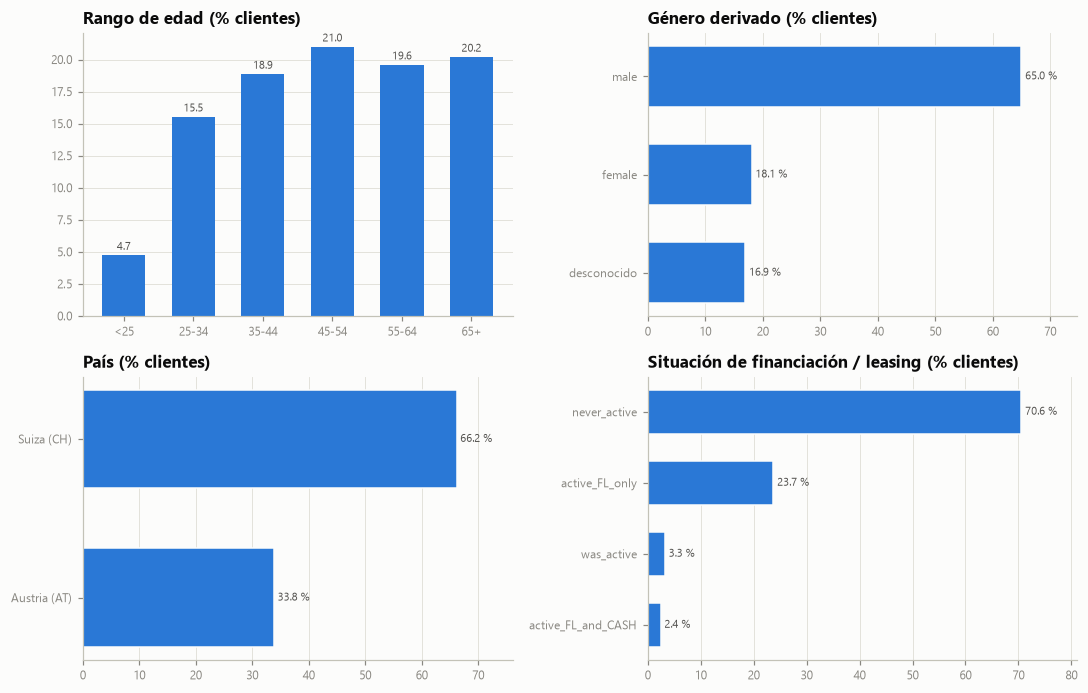

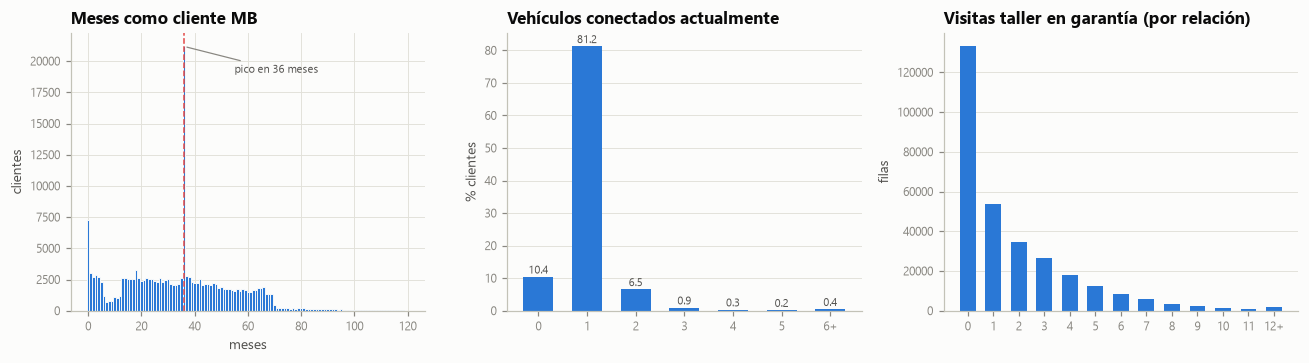

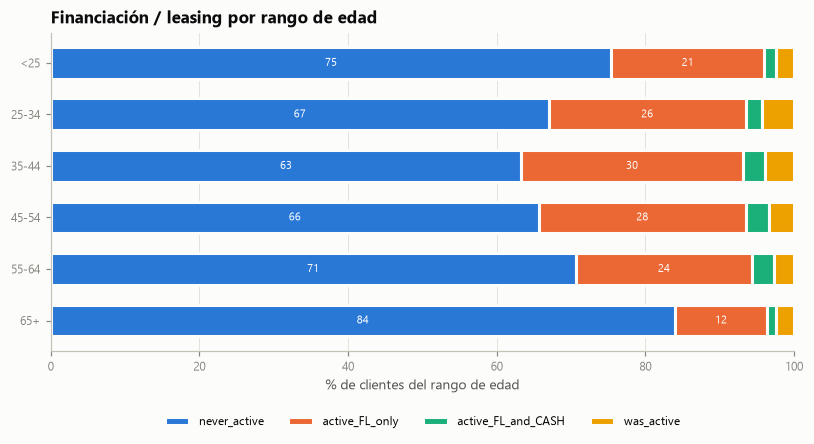

In [13]:
# Figuras demográficas
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
a = cl.age_range.value_counts().reindex(AGE_ORDER)
axes[0, 0].bar(a.index, a.values / len(cl) * 100, width=0.62, color=BLUE)
axes[0, 0].set_title("Rango de edad (% clientes)"); axes[0, 0].grid(axis="x", visible=False)
for i, v in enumerate(a.values / len(cl) * 100):
    axes[0, 0].text(i, v + 0.4, f"{v:.1f}", ha="center", fontsize=7.5, color=INK2)
gd = cl.gender_derived.fillna("desconocido").value_counts() / len(cl) * 100
barh(axes[0, 1], gd, fmt="{:.1f} %", title="Género derivado (% clientes)")
ct = cl.country_code.value_counts() / len(cl) * 100
barh(axes[1, 0], ct.rename({"CH": "Suiza (CH)", "AT": "Austria (AT)"}), fmt="{:.1f} %", title="País (% clientes)")
fl = cl.finance_leasing_status.value_counts() / len(cl) * 100
barh(axes[1, 1], fl, fmt="{:.1f} %", title="Situación de financiación / leasing (% clientes)")
save(fig, "fig05_perfil_cliente.png")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
mm = cl.months_as_mb_customer.dropna()
axes[0].hist(mm, bins=np.arange(-0.5, 121.5, 1), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
axes[0].axvline(36, color=CAT[7], lw=1, ls="--")
axes[0].annotate("pico en 36 meses", xy=(36, (mm == 36).sum()), xytext=(55, (mm == 36).sum() * 0.9),
                 fontsize=7.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[0].set_title("Meses como cliente MB"); axes[0].set_xlabel("meses"); axes[0].set_ylabel("clientes")
cv = cl.currently_connected_vehicles.clip(upper=6).value_counts().sort_index()
axes[1].bar([str(i) if i < 6 else "6+" for i in cv.index], cv.values / len(cl) * 100, width=0.62, color=BLUE)
axes[1].set_title("Vehículos conectados actualmente"); axes[1].set_ylabel("% clientes"); axes[1].grid(axis="x", visible=False)
for i, v in enumerate(cv.values / len(cl) * 100):
    axes[1].text(i, v + 1, f"{v:.1f}", ha="center", fontsize=7.5, color=INK2)
wv = df.workshop_visits_warranty_goodwill.clip(upper=12)
w = wv.value_counts().sort_index()
axes[2].bar([str(i) if i < 12 else "12+" for i in w.index], w.values, width=0.62, color=BLUE)
axes[2].set_title("Visitas taller en garantía (por relación)"); axes[2].set_ylabel("filas"); axes[2].grid(axis="x", visible=False)
save(fig, "fig06_relacion_marca.png")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ct6 = pd.crosstab(cl.age_range, cl.finance_leasing_status, normalize="index").reindex(AGE_ORDER).mul(100)
ct6 = ct6[["never_active", "active_FL_only", "active_FL_and_CASH", "was_active"]]
left = np.zeros(len(ct6))
for i, col in enumerate(ct6.columns):
    ax.barh(ct6.index, ct6[col], left=left, height=0.62, color=CAT[i], edgecolor=SURFACE, linewidth=2, label=col)
    for j, v in enumerate(ct6[col].values):
        if v > 6:
            ax.text(left[j] + v / 2, j, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white")
    left += ct6[col].values
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de clientes del rango de edad")
ax.set_title("Financiación / leasing por rango de edad")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))
save(fig, "fig07_financiacion_edad.png")

## 7. Vehículo

- Dominan GLC, C, A y B/GLA/GLB. El 59 % es 4MATIC, el 13 % es AMG y el 14 % son furgonetas.
- La electrificación se acelera: los BEV pasan del 2,5 % de las matriculaciones de 2019 al 37,5 % de las de 2026.
  Austria está más electrificada que Suiza.
- Las visitas en garantía crecen hasta los 4–5 años de antigüedad.

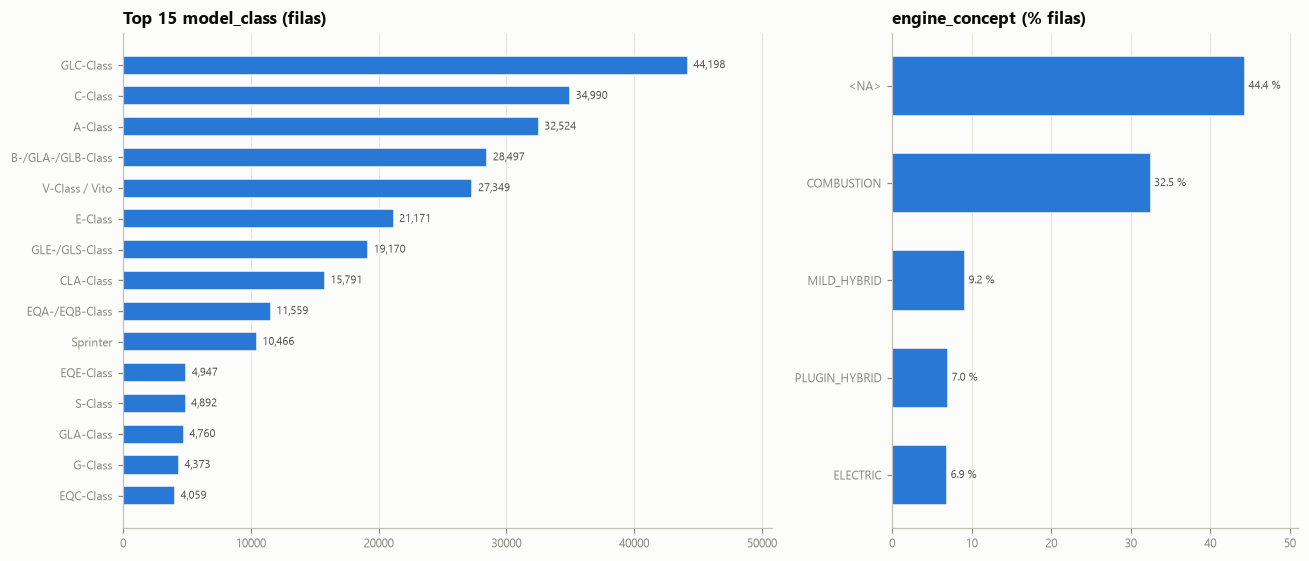

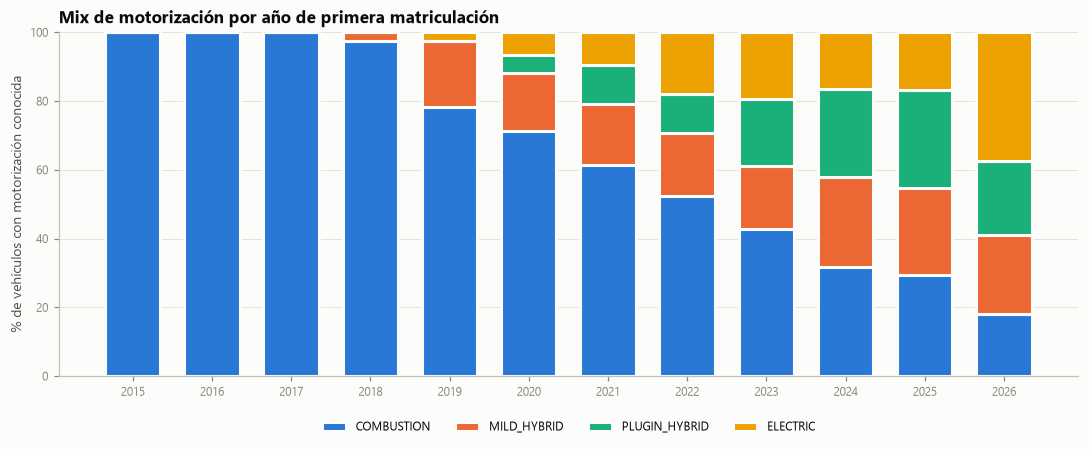


### 7.1 Mix de motorización por año de matriculación (% sobre conocidos)

|   reg_year |   COMBUSTION |   MILD_HYBRID |   PLUGIN_HYBRID |   ELECTRIC |
|-----------:|-------------:|--------------:|----------------:|-----------:|
|       2015 |        100.0 |           0.0 |             0.0 |        0.0 |
|       2016 |        100.0 |           0.0 |             0.0 |        0.0 |
|       2017 |        100.0 |           0.0 |             0.0 |        0.0 |
|       2018 |         97.4 |           2.6 |             0.0 |        0.0 |
|       2019 |         78.2 |          19.2 |             0.1 |        2.5 |
|       2020 |         71.2 |          17.0 |             5.0 |        6.7 |
|       2021 |         61.3 |          17.9 |            11.2 |        9.6 |
|       2022 |         52.4 |          18.3 |            11.2 |       18.1 |
|       2023 |         42.8 |          18.3 |            19.6 |       19.3 |
|       2024 |         31.7 |          26.2 |            25.6 |       16.5 |
|       2025 |         29.4 |          25.2 |            28.6 |       16.8 |
|       2026 |         18.2 |          22.8 |            21.5 |       37.5 |


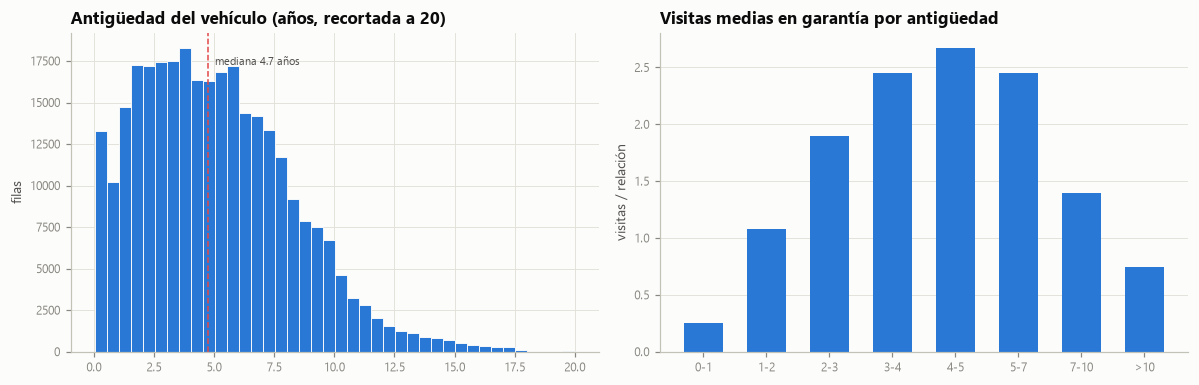


### 7.2 Visitas en garantía medias por antigüedad del vehículo

| vehicle_age_years   |   visitas medias |
|:--------------------|-----------------:|
| (0, 1]              |             0.25 |
| (1, 2]              |             1.08 |
| (2, 3]              |             1.90 |
| (3, 4]              |             2.45 |
| (4, 5]              |             2.67 |
| (5, 7]              |             2.45 |
| (7, 10]             |             1.39 |
| (10, 40]            |             0.75 |



### 7.3 product_group

| product_group   |   filas |   % filas | significado (deducido de model_class)                              |
|:----------------|--------:|----------:|:-------------------------------------------------------------------|
| P               |  255604 |     84.40 | Turismos                                                           |
| T               |   41937 |     13.85 | Furgonetas / transporter (V-Class, Vito, Sprinter, Citan, X-Class) |
| G               |    4373 |      1.44 | Clase G (todoterreno)                                              |
| F               |     936 |      0.31 | smart (fortwo/forfour)                                             |



### 7.4 Señales de gama extraíbles de vehicle_type

|                                      |   % filas |
|:-------------------------------------|----------:|
| AMG (vehicle_type empieza por 'AMG') |     12.76 |
| 4MATIC (tracción integral)           |     58.90 |
| Maybach                              |      0.14 |



### 7.5 engine_concept por país (% fila, sobre conocidos)

| country_code   |   COMBUSTION |   ELECTRIC |   MILD_HYBRID |   PLUGIN_HYBRID |
|:---------------|-------------:|-----------:|--------------:|----------------:|
| AT             |         54.7 |       16.7 |          11.8 |            16.8 |
| CH             |         60.6 |        9.9 |          19.2 |            10.2 |


In [14]:
# ==========================================================================
# 7. VEHÍCULO
# ==========================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
mct = df.model_class.fillna("<sin clase>").value_counts().head(15)
barh(axes[0], mct, title="Top 15 model_class (filas)")
ecv = df.engine_concept.fillna("<NA>").value_counts()
barh(axes[1], ecv / len(df) * 100, fmt="{:.1f} %", title="engine_concept (% filas)")
save(fig, "fig08_vehiculo_clase_motor.png")

fig, ax = plt.subplots(figsize=(10, 4.2))
ey = df[(df.reg_year >= 2015) & df.engine_concept.notna()]
ey = pd.crosstab(ey.reg_year.astype(int), ey.engine_concept, normalize="index").mul(100)[
    ["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC"]]
bottom = np.zeros(len(ey))
for i, col in enumerate(ey.columns):
    ax.bar(ey.index.astype(str), ey[col], bottom=bottom, width=0.7, color=CAT[i], edgecolor=SURFACE, linewidth=2, label=col)
    bottom += ey[col].values
ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_ylabel("% de vehículos con motorización conocida")
ax.set_title("Mix de motorización por año de primera matriculación")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "fig09_electrificacion_por_anio.png")
md("7.1 Mix de motorización por año de matriculación (% sobre conocidos)", ey, floatfmt=".1f")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
va = df.vehicle_age_years.dropna()
axes[0].hist(va.clip(upper=20), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
axes[0].axvline(va.median(), color=CAT[7], lw=1, ls="--")
axes[0].text(va.median() + 0.3, axes[0].get_ylim()[1] * 0.9, f"mediana {va.median():.1f} años", fontsize=7.5, color=INK2)
axes[0].set_title("Antigüedad del vehículo (años, recortada a 20)"); axes[0].set_ylabel("filas")
wb = df.groupby(pd.cut(df.vehicle_age_years, [0, 1, 2, 3, 4, 5, 7, 10, 40])).workshop_visits_warranty_goodwill.mean()
axes[1].bar(["0-1", "1-2", "2-3", "3-4", "4-5", "5-7", "7-10", ">10"], wb.values, width=0.62, color=BLUE)
axes[1].set_title("Visitas medias en garantía por antigüedad"); axes[1].set_ylabel("visitas / relación")
axes[1].grid(axis="x", visible=False)
save(fig, "fig10_antiguedad_taller.png")
md("7.2 Visitas en garantía medias por antigüedad del vehículo", wb.rename("visitas medias"), floatfmt=".2f")

pgt = df.product_group.value_counts().rename("filas").to_frame()
pgt["% filas"] = pgt.filas / len(df) * 100
pgt["significado (deducido de model_class)"] = pgt.index.map(
    {"P": "Turismos", "T": "Furgonetas / transporter (V-Class, Vito, Sprinter, Citan, X-Class)",
     "G": "Clase G (todoterreno)", "F": "smart (fortwo/forfour)"})
md("7.3 product_group", pgt, floatfmt=",.2f")
flags = pd.Series({
    "AMG (vehicle_type empieza por 'AMG')": df.vehicle_type.fillna("").str.startswith("AMG").mean() * 100,
    "4MATIC (tracción integral)": df.vehicle_type.fillna("").str.contains("4MATIC").mean() * 100,
    "Maybach": df.vehicle_type.fillna("").str.contains("Maybach", case=False).mean() * 100,
}, name="% filas")
md("7.4 Señales de gama extraíbles de vehicle_type", flags, floatfmt=".2f")
md("7.5 engine_concept por país (% fila, sobre conocidos)",
   pd.crosstab(df.country_code, df.engine_concept, normalize="index").mul(100), floatfmt=".1f")

## 8. Socio-demografía, uso y correlaciones

- El poder adquisitivo depende sobre todo del país: mediana de 30 k€ por habitante en AT frente a 51 k€ en CH.
  Conviene estandarizarlo dentro de cada país.
- Uso típico: trayectos de 14 km a 49 km/h y unas 400 h acumuladas.
- El consumo es coherente con el combustible: diésel < gasolina < súper plus (AMG).

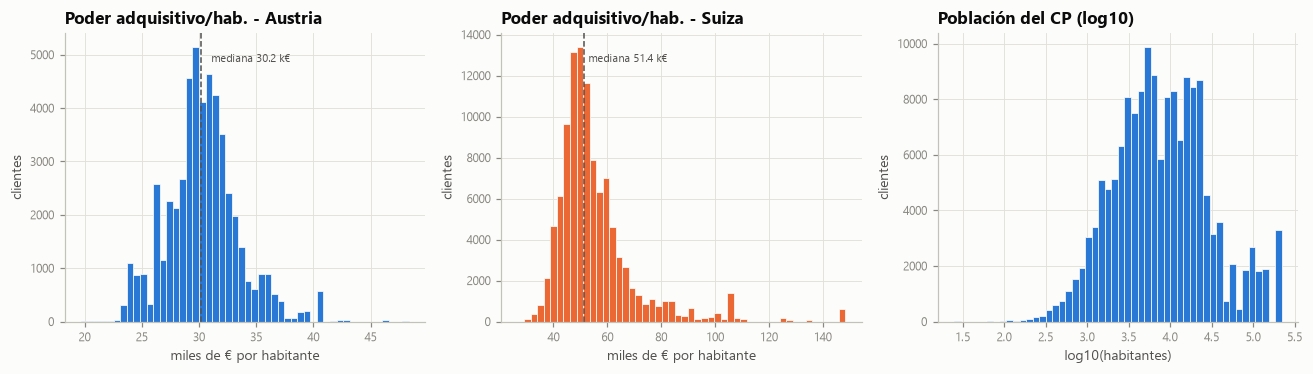


### 8.1 Socio-demografía por país (mediana, nivel cliente)

| country_code   |   purchasing_power_per_inhabitant_eur |   purchasing_power_per_household_eur |   population |   number_of_households |   purchasing_power_millions_eur |
|:---------------|--------------------------------------:|-------------------------------------:|-------------:|-----------------------:|--------------------------------:|
| AT             |                              30,177.6 |                             66,938.2 |      9,856.0 |                4,580.0 |                           309.7 |
| CH             |                              51,433.6 |                            116,082.4 |      6,695.0 |                2,979.0 |                           374.4 |


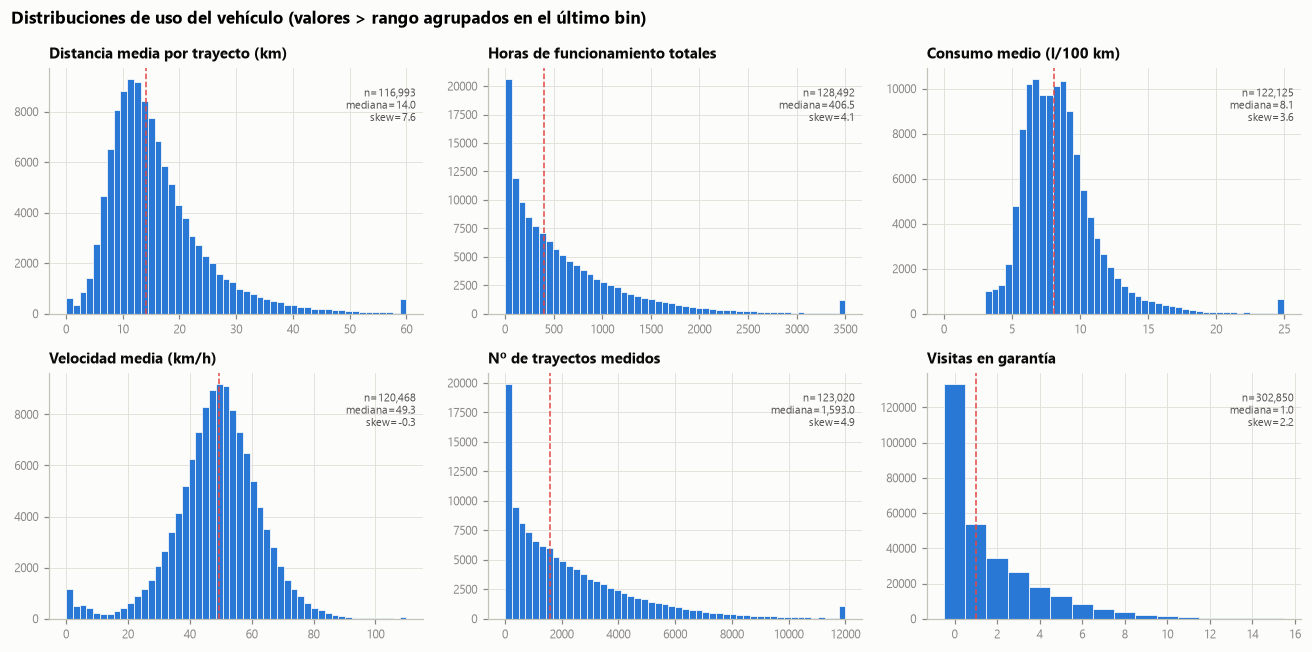

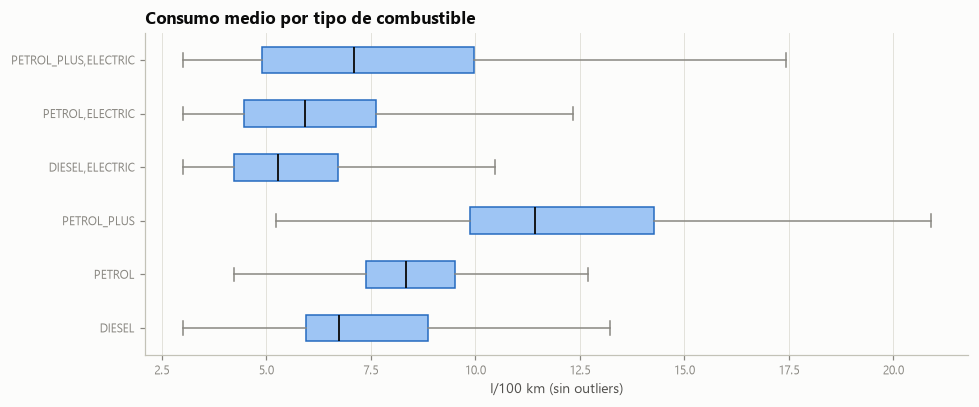

In [15]:
# ==========================================================================
# 8. SOCIO-DEMOGRAFÍA Y TELEMETRÍA: DISTRIBUCIONES
# ==========================================================================
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for i, (cc_, lab) in enumerate([("AT", "Austria"), ("CH", "Suiza")]):
    x = cl.loc[cl.country_code == cc_, "purchasing_power_per_inhabitant_eur"].dropna() / 1000
    axes[i].hist(x, bins=50, color=CAT[i], edgecolor=SURFACE, linewidth=0.5)
    axes[i].axvline(x.median(), color=INK2, lw=1, ls="--")
    axes[i].text(x.median() * 1.03, axes[i].get_ylim()[1] * 0.9, f"mediana {x.median():.1f} k€", fontsize=7.5, color=INK2)
    axes[i].set_title(f"Poder adquisitivo/hab. - {lab}")
    axes[i].set_xlabel("miles de € por habitante"); axes[i].set_ylabel("clientes")
pop = cl.population.dropna()
axes[2].hist(np.log10(pop[pop > 0]), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[2].set_title("Población del CP (log10)"); axes[2].set_xlabel("log10(habitantes)"); axes[2].set_ylabel("clientes")
save(fig, "fig11_socio_demografia.png")
md("8.1 Socio-demografía por país (mediana, nivel cliente)", cl.groupby("country_code")[SOCIO].median(), floatfmt=",.1f")

tel_num = [("trip_distance_average", "Distancia media por trayecto (km)", (0, 60)),
           ("operating_hours_total", "Horas de funcionamiento totales", (0, 3500)),
           ("fuel_consumption_average", "Consumo medio (l/100 km)", (0, 25)),
           ("speed_average", "Velocidad media (km/h)", (0, 110)),
           ("trip_distance_all_counter", "Nº de trayectos medidos", (0, 12000)),
           ("workshop_visits_warranty_goodwill", "Visitas en garantía", (0, 15))]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (c, lab, rng) in zip(axes.flat, tel_num):
    x = df[c].dropna()
    b = np.arange(rng[0] - 0.5, rng[1] + 1.5, 1) if c == "workshop_visits_warranty_goodwill" else 50
    ax.hist(x.clip(*rng), bins=b, range=None if c == "workshop_visits_warranty_goodwill" else rng, color=BLUE,
            edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(x.median(), color=CAT[7], lw=1, ls="--")
    ax.set_title(lab, fontsize=9.5)
    ax.text(0.98, 0.92, f"n={len(x):,}\nmediana={x.median():,.1f}\nskew={x.skew():.1f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color=INK2)
fig.suptitle("Distribuciones de uso del vehículo (valores > rango agrupados en el último bin)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
save(fig, "fig12_distribuciones_telemetria.png")

fig, ax = plt.subplots(figsize=(9, 3.8))
order = ["DIESEL", "PETROL", "PETROL_PLUS", "DIESEL,ELECTRIC", "PETROL,ELECTRIC", "PETROL_PLUS,ELECTRIC"]
data = [df.loc[df.fuel_type == f, "fuel_consumption_average"].dropna().values for f in order]
bp = ax.boxplot(data, orientation="horizontal", widths=0.5, showfliers=False, patch_artist=True,
                medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for b in bp["boxes"]:
    b.set(facecolor=SEQ[1], edgecolor=SEQ[4])
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order)
ax.set_xlabel("l/100 km (sin outliers)"); ax.grid(axis="y", visible=False)
ax.set_title("Consumo medio por tipo de combustible")
save(fig, "fig13_consumo_por_combustible.png")

### 8.1 Correlaciones

Hay bloques redundantes (|ρ| ≥ 0,93): población ↔ hogares ↔ PA total, PA/habitante ↔ PA/hogar, y horas ↔
contadores. Fuera de esos bloques, casi todas las variables son independientes (|ρ| < 0,3), así que cada bloque
aporta información distinta para segmentar. Hay relaciones con sentido de negocio, como más uso → más taller
(ρ = 0,38–0,45).

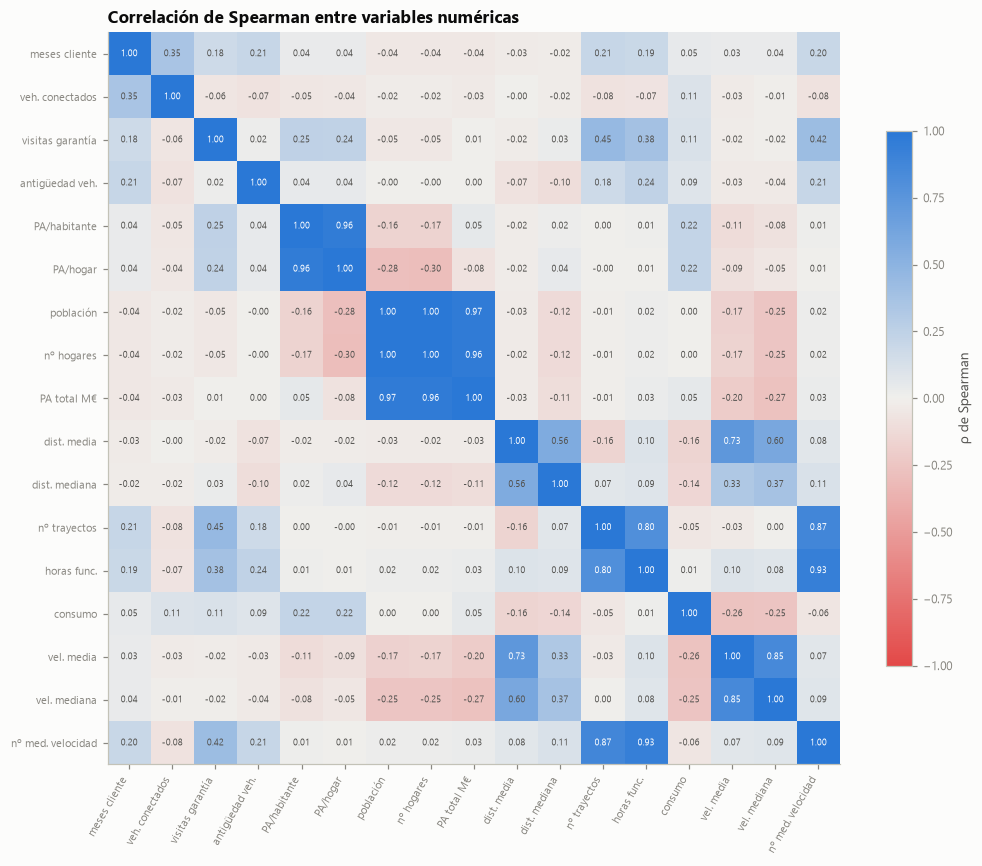


### 8.2 Pares con |ρ| ≥ 0,7 (candidatos a redundancia)

|                                                                          |   ρ Spearman |
|:-------------------------------------------------------------------------|-------------:|
| population ↔ number_of_households                                        |        0.998 |
| population ↔ purchasing_power_millions_eur                               |        0.967 |
| number_of_households ↔ purchasing_power_millions_eur                     |        0.965 |
| purchasing_power_per_inhabitant_eur ↔ purchasing_power_per_household_eur |        0.956 |
| operating_hours_total ↔ speed_all_counter                                |        0.930 |
| trip_distance_all_counter ↔ speed_all_counter                            |        0.870 |
| speed_average ↔ speed_median                                             |        0.846 |
| trip_distance_all_counter ↔ operating_hours_total                        |        0.799 |
| trip_distance_average ↔ speed_average                                    |        0.733 |


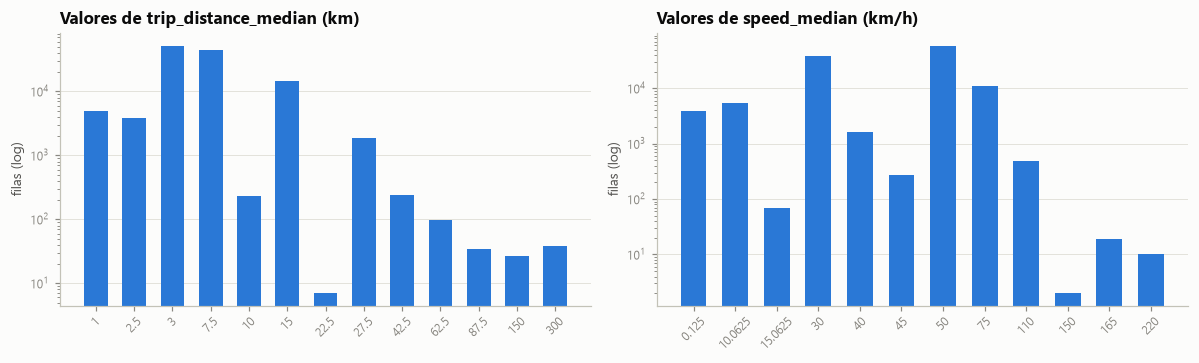

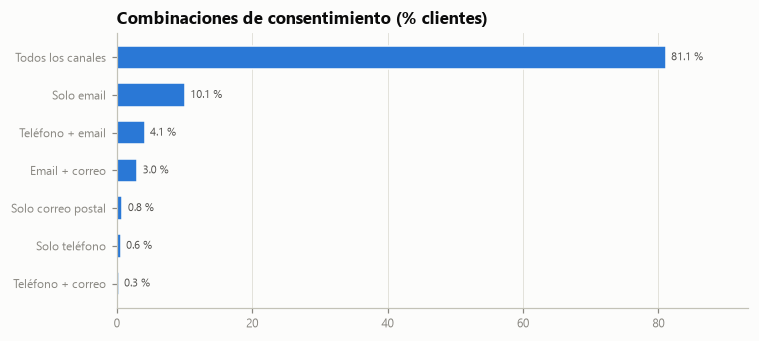

In [16]:
# Correlación de Spearman
corr_cols = ["months_as_mb_customer", "currently_connected_vehicles", "workshop_visits_warranty_goodwill",
             "vehicle_age_years", "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
             "population", "number_of_households", "purchasing_power_millions_eur", "trip_distance_average",
             "trip_distance_median", "trip_distance_all_counter", "operating_hours_total",
             "fuel_consumption_average", "speed_average", "speed_median", "speed_all_counter"]
corr = df[corr_cols].corr(method="spearman")
short = {"months_as_mb_customer": "meses cliente", "currently_connected_vehicles": "veh. conectados",
         "workshop_visits_warranty_goodwill": "visitas garantía", "vehicle_age_years": "antigüedad veh.",
         "purchasing_power_per_inhabitant_eur": "PA/habitante", "purchasing_power_per_household_eur": "PA/hogar",
         "population": "población", "number_of_households": "nº hogares", "purchasing_power_millions_eur": "PA total M€",
         "trip_distance_average": "dist. media", "trip_distance_median": "dist. mediana",
         "trip_distance_all_counter": "nº trayectos", "operating_hours_total": "horas func.",
         "fuel_consumption_average": "consumo", "speed_average": "vel. media", "speed_median": "vel. mediana",
         "speed_all_counter": "nº med. velocidad"}
fig, ax = plt.subplots(figsize=(9.5, 8))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("div", DIV)
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels([short[c] for c in corr.columns], rotation=60, ha="right", fontsize=7.5)
ax.set_yticklabels([short[c] for c in corr.index], fontsize=7.5)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 else INK2)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlación de Spearman entre variables numéricas")
save(fig, "fig14_correlacion_spearman.png")
strong = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
strong = strong[strong.abs() >= 0.7].sort_values(key=abs, ascending=False).rename("ρ Spearman")
strong.index = [f"{a} ↔ {b}" for a, b in strong.index]
md("8.2 Pares con |ρ| ≥ 0,7 (candidatos a redundancia)", strong, floatfmt=".3f")

# Bins de mediana: dos esquemas
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
tm = df.trip_distance_median.value_counts().sort_index()
axes[0].bar([f"{v:g}" for v in tm.index], tm.values, width=0.62, color=BLUE)
axes[0].set_yscale("log"); axes[0].set_title("Valores de trip_distance_median (km)"); axes[0].set_ylabel("filas (log)")
axes[0].grid(axis="x", visible=False); axes[0].tick_params(axis="x", rotation=45)
sm = df.speed_median.round(4).value_counts().sort_index()
axes[1].bar([f"{v:g}" for v in sm.index], sm.values, width=0.62, color=BLUE)
axes[1].set_yscale("log"); axes[1].set_title("Valores de speed_median (km/h)"); axes[1].set_ylabel("filas (log)")
axes[1].grid(axis="x", visible=False); axes[1].tick_params(axis="x", rotation=45)
save(fig, "fig15_medianas_discretizadas.png")

# Consentimientos
fig, ax = plt.subplots(figsize=(7, 3.2))
names = {"111": "Todos los canales", "010": "Solo email", "110": "Teléfono + email", "011": "Email + correo",
         "001": "Solo correo postal", "100": "Solo teléfono", "101": "Teléfono + correo", "000": "Ninguno"}
c2 = (cc / len(cl) * 100).rename(index=names)
barh(ax, c2, fmt="{:.1f} %", title="Combinaciones de consentimiento (% clientes)")
save(fig, "fig16_consentimientos.png")

## 9. Tratamiento de nulos

Se parte de la decisión del equipo (`Descripcion_uso_de_datos`). El documento nombra las columnas por su
letra al abrir el CSV en Excel (A = índice sin nombre, …, AM = `purchasing_power_millions_eur`).

Aplicada al pie de la letra, esa decisión generaba **incoherencias** en el dataset:

| Regla original | Incoherencia | Corrección aplicada |
|---|---|---|
| J: motor nulo → moda (COMBUSTION) | 7.114 vehículos `EQ…` (eléctricos) quedaban como combustión; la combustión subía del 58 % al 77 % | Cascada de reglas validadas (nombre comercial, serie, año; 99–100 % de acierto). La moda solo se usa para lo que queda: primero la de su serie y después la global |
| L: combustible derivado de J por moda | 71.283 turismos de gasolina quedaban como DIESEL | Se sigue derivando de J, pero con el nombre comercial (`d`/CDI/BlueTEC → diésel; furgoneta → diésel; resto → gasolina; PHEV `de` → diésel-eléctrico) |
| AA: CP aleatorio entre el mín. y el máx. | El 68 % de los CP generados no existía; un mismo cliente podía recibir CP distintos en cada fila | CP sorteado **entre los CP reales** del país con datos, ponderado por nº de clientes y **uno por cliente** |
| X, Y, Z, AL, AM: media/moda del CP | Nunca aplicable a CP existentes (el dato es constante por CP); rellenos independientes rompían las identidades PA total = PA/hab × población | Valor del CP (real o sorteado). Si el CP no tiene datos, mediana de la región para X y Z, y **Y, AL y AM se recalculan** con las identidades |
| AB–AG → 0 y AH → moda de la serie | Filas sin telemetría con distancia y consumo 0 pero velocidad 50 km/h; filas parciales con 0 trayectos y cientos de horas | **Sin telemetría:** todo a 0, también velocidad y contadores. **Telemetría parcial:** la métrica que falta toma la mediana de su serie (AH: moda de su serie; AC/AI: moda de la serie, que es un bin válido; consumo de un eléctrico: 0) |
| AK: contador nulo → 1 | Contador 1 con velocidad 0 | 0 si no hay telemetría; mediana de la serie si es parcial |
| `population = 0` | PA por habitante imputado con población 0 | Se trata como CP sin datos (respaldo de región) |

El resto de reglas del documento se aplica tal cual: E → `unknown`, G → moda de su serie, Q → 0, N/O/P/R/S/T/U/V/W
(sin nulos en este extracto) y eliminar A, B, C y H. **M** (fecha de matriculación, "?" en el documento) sigue
**pendiente**: provisionalmente se usa la mediana de su serie, con un flag.

Cada relleno deja un flag (`has_telemetry`, `tel_partial`, `zip_imputed`, `socio_imputed`, `engine_imputed`,
`fuel_imputed`, `reg_date_imputed`) para poder aislar su efecto en el clustering.

In [17]:
print("Aplicando tratamiento...")
RAW_COLS = list(raw.columns)


def col_letter(i: int) -> str:
    s = ""
    i += 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s


L = {col_letter(i): c for i, c in enumerate(RAW_COLS)}  # L["AA"] -> "zipcode"
DECISION = {
    "A": "Quitar (ruido)", "B": "Quitar (ruido) · se conserva solo como clave", "C": "Quitar (ruido) · se conserva solo como clave",
    "D": "Sin nulos", "E": "Nulos → 'unknown'", "F": "Sin nulos", "G": "Nulos → moda de su model_series",
    "H": "Quitar (ruido): función exacta de F", "I": "Sin nulos",
    "J": "Nulos → cascada validada (nombre, serie, año) → moda de la serie → moda global",
    "K": "Sin nulos", "L": "Nulos → derivado de J + nombre comercial",
    "M": "PENDIENTE (?): provisional mediana de su serie + flag", "N": "Nulos → False",
    "O": "Nulos → OWNER (moda)", "P": "Nulos → B2C (moda)", "Q": "Nulos → 0.0", "R": "Nulos → 1 (moda)",
    "S": "Nulos → never_active", "T": "Nulos → moda", "U": "Nulos → False", "V": "Nulos → False", "W": "Nulos → False",
    "X": "Valor de su CP · respaldo mediana región/país", "Y": "Valor de su CP · si no, recalculado = AM×1e6/AL",
    "Z": "Valor de su CP · respaldo mediana región/país",
    "AA": "Nulos → CP real del país sorteado (ponderado, uno por cliente)",
    **{k: "Sin telemetría → 0 · parcial → mediana de su serie" for k in ["AB", "AD", "AE", "AF"]},
    "AC": "Sin telemetría → '0' · parcial → moda de su serie",
    "AG": "Sin telemetría → 0 · parcial → 0 si ELECTRIC, si no mediana de su serie",
    "AH": "Sin telemetría → 0 · parcial → velocidad moda de su serie",
    "AI": "Sin telemetría → '0' · parcial → moda de su serie",
    "AJ": "Sin telemetría → 0 · parcial → mediana de su serie",
    "AK": "Sin telemetría → 0 · parcial → mediana de su serie",
    "AL": "Valor de su CP · si no, = población / tamaño medio del hogar de la región",
    "AM": "Valor de su CP · si no, = X × Z / 1e6",
}
mapping = pd.DataFrame({"letra": list(L), "columna": list(L.values()),
                        "nulos originales": [raw[c].isna().sum() for c in L.values()],
                        "tratamiento aplicado": [DECISION.get(k, "—") for k in L]})
md("9.1 Columnas (letra del documento) y tratamiento aplicado", mapping, index=False, floatfmt=",.0f")

Aplicando tratamiento...



### 9.1 Columnas (letra del documento) y tratamiento aplicado

| letra   | columna                             |   nulos originales | tratamiento aplicado                                                           |
|:--------|:------------------------------------|-------------------:|:-------------------------------------------------------------------------------|
| A       | Unnamed: 0                          |                  0 | Quitar (ruido)                                                                 |
| B       | client_id                           |                  0 | Quitar (ruido) · se conserva solo como clave                                   |
| C       | vehicle_id                          |                  0 | Quitar (ruido) · se conserva solo como clave                                   |
| D       | age_range                           |                  0 | Sin nulos                                                                      |
| E       | gender_derived                      |              33923 | Nulos → 'unknown'                                                              |
| F       | model_series                        |                  0 | Sin nulos                                                                      |
| G       | vehicle_type                        |                922 | Nulos → moda de su model_series                                                |
| H       | model_class                         |               3369 | Quitar (ruido): función exacta de F                                            |
| I       | product_group                       |                  0 | Sin nulos                                                                      |
| J       | engine_concept                      |             134390 | Nulos → cascada validada (nombre, serie, año) → moda de la serie → moda global |
| K       | country_code                        |                  0 | Sin nulos                                                                      |
| L       | fuel_type                           |             178745 | Nulos → derivado de J + nombre comercial                                       |
| M       | date_of_first_registration          |               4182 | PENDIENTE (?): provisional mediana de su serie + flag                          |
| N       | is_current_vehicle                  |                  0 | Nulos → False                                                                  |
| O       | role                                |                  0 | Nulos → OWNER (moda)                                                           |
| P       | role_type                           |                  0 | Nulos → B2C (moda)                                                             |
| Q       | months_as_mb_customer               |                  4 | Nulos → 0.0                                                                    |
| R       | currently_connected_vehicles        |                  0 | Nulos → 1 (moda)                                                               |
| S       | finance_leasing_status              |                  0 | Nulos → never_active                                                           |
| T       | workshop_visits_warranty_goodwill   |                  0 | Nulos → moda                                                                   |
| U       | consent_phone_communication_channel |                  0 | Nulos → False                                                                  |
| V       | consent_epost_communication_channel |                  0 | Nulos → False                                                                  |
| W       | consent_post_communication_channel  |                  0 | Nulos → False                                                                  |
| X       | purchasing_power_per_inhabitant_eur |              19087 | Valor de su CP · respaldo mediana región/país                                  |
| Y       | purchasing_power_per_household_eur  |              19087 | Valor de su CP · si no, recalculado = AM×1e6/AL                                |
| Z       | population                          |              19014 | Valor de su CP · respaldo mediana región/país                                  |
| AA      | zipcode                             |              16135 | Nulos → CP real del país sorteado (ponderado, uno por cliente)                 |
| AB      | trip_distance_average               |             185857 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AC      | trip_distance_mode                  |             179830 | Sin telemetría → '0' · parcial → moda de su serie                              |
| AD      | trip_distance_median                |             179830 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AE      | trip_distance_all_counter           |             179830 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AF      | operating_hours_total               |             174358 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AG      | fuel_consumption_average            |             180725 | Sin telemetría → 0 · parcial → 0 si ELECTRIC, si no mediana de su serie        |
| AH      | speed_average                       |             182382 | Sin telemetría → 0 · parcial → velocidad moda de su serie                      |
| AI      | speed_mode                          |             181159 | Sin telemetría → '0' · parcial → moda de su serie                              |
| AJ      | speed_median                        |             181159 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AK      | speed_all_counter                   |             181159 | Sin telemetría → 0 · parcial → mediana de su serie                             |
| AL      | number_of_households                |              19014 | Valor de su CP · si no, = población / tamaño medio del hogar de la región      |
| AM      | purchasing_power_millions_eur       |              19087 | Valor de su CP · si no, = X × Z / 1e6                                          |


### 9.2 Limpieza previa y flags

Antes de rellenar se corrigen los valores erróneos detectados en la §4 (no son nulos, pero son imposibles)
y se guardan los flags que indican qué dato era ausente.

In [18]:
t = df.drop(columns=["has_telemetry", "reg_year", "vehicle_age_years"]).copy()
t["reg_year"] = df.reg_year
log = []


def step(letra, desc, n):
    log.append({"letra": letra, "columna": L.get(letra, "—"), "tratamiento": desc, "valores": int(n)})


def fill(col, values, letra, desc, mask=None):
    m = t[col].isna() if mask is None else (mask & t[col].isna())
    if isinstance(values, pd.Series):
        t.loc[m, col] = values[m]
    else:
        t.loc[m, col] = values
    step(letra, desc, (m & t[col].notna()).sum())


def series_mode(s: pd.Series):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan


# CP con formato erróneo y zonas sin población
bad_zip = t.zipcode.notna() & ~t.zipcode.str.fullmatch(r"\d{4}")
t.loc[bad_zip, "zipcode"] = t.loc[bad_zip, "zipcode"].str.extract(r"^(?:A-|CH-)?(\d{4})$")[0]
step("AA", "CP normalizado ('A-'/'CH-' fuera; texto o 5 dígitos → nulo)", bad_zip.sum())
z0 = t.population == 0
t.loc[z0, SOCIO] = np.nan
step("Z/AL", "population = 0 (CP sin residentes) → zona sin datos", z0.sum())

# Telemetría: valores imposibles → nulo; winsorización p1-p99 de lo observado
n_before = t[TELEMETRY].notna().sum().sum()
t.loc[t.speed_average < 1, "speed_average"] = np.nan
t.loc[t.operating_hours_total <= 0, "operating_hours_total"] = np.nan
t.loc[t.trip_distance_all_counter == 0, ["trip_distance_average", "trip_distance_median", "trip_distance_mode",
                                         "trip_distance_all_counter"]] = np.nan
t.loc[t.speed_all_counter == 0, ["speed_average", "speed_median", "speed_mode", "speed_all_counter"]] = np.nan
t["speed_median"] = t.speed_median.round(4)
step("AB–AK", "valores imposibles (vel. < 1, horas = 0, contadores = 0 con métricas) → nulo",
     n_before - t[TELEMETRY].notna().sum().sum())
for letra in ["AB", "AF", "AG", "AH"]:
    c = L[letra]
    lo, hi = t[c].quantile([.01, .99])
    step(letra, f"winsorización p1–p99 de los observados [{lo:,.2f}; {hi:,.2f}]", ((t[c] < lo) | (t[c] > hi)).sum())
    t[c] = t[c].clip(lo, hi)

# Flags (antes de rellenar)
t["has_telemetry"] = t[TELEMETRY].notna().any(axis=1)
t["tel_partial"] = t.has_telemetry & t[TELEMETRY].isna().any(axis=1)
t["socio_imputed"] = t[SOCIO].isna().any(axis=1)
t["zip_imputed"] = t.zipcode.isna()
t["engine_imputed"] = t.engine_concept.isna()
t["fuel_imputed"] = t.fuel_type.isna()
t["reg_date_imputed"] = t.reg_date.isna()
t["months_is_36_spike"] = t.months_as_mb_customer == 36
before = t.copy()
pd.Series({"filas con telemetría completa": (t.has_telemetry & ~t.tel_partial).sum(),
           "filas con telemetría parcial": t.tel_partial.sum(),
           "filas sin telemetría": (~t.has_telemetry).sum()}, name="filas").to_frame()

,filas
filas con telemetría completa,96664
filas con telemetría parcial,48001
filas sin telemetría,158185


### 9.3 Perfil, vehículo y motorización (D–M)

Las reglas de motorización se validan antes sobre las filas cuya motorización sí se conoce.

In [19]:
def name_rule(vt):
    if not isinstance(vt, str):
        return np.nan
    v = vt.upper()
    if v.startswith(("EQ", "AMG EQ")) or "ELECTRIC" in v or re.match(r"^(E-?SPRINTER|E-?VITO|E-?CITAN|EQV)", v.replace(" ", "")):
        return "ELECTRIC"
    if re.search(r"\b\d{3}\s?(E|DE)\b", v) or "HYBRID" in v or "E PERFORMANCE" in v:
        return "PLUGIN_HYBRID"
    return np.nan


def is_diesel_name(s: pd.Series) -> pd.Series:
    return s.fillna("").str.contains(r"\b\d{3}\s?d\b|\bd\s?4MATIC|CDI|BLUETEC|\b\d{3}\s?de\b", case=False, regex=True)


def consistent_lookup(key):
    k = df.dropna(subset=["engine_concept"])
    return k.groupby(key).engine_concept.agg(
        lambda s: s.mode().iloc[0] if s.value_counts(normalize=True).iloc[0] >= .9 else np.nan).dropna()


def fuel_from_engine(d: pd.DataFrame) -> pd.Series:
    dn = is_diesel_name(d.vehicle_type)
    ec = d.engine_concept
    return pd.Series(np.select(
        [ec == "ELECTRIC", (ec == "PLUGIN_HYBRID") & dn, ec == "PLUGIN_HYBRID", dn | (d.product_group == "T")],
        ["ELECTRIC", "DIESEL,ELECTRIC", "PETROL,ELECTRIC", "DIESEL"], "PETROL"), index=d.index)


k = df[df.engine_concept.notna()]
nr = k.vehicle_type.map(name_rule)
old = k[(k.reg_year <= 2018) & nr.isna()]
kf = df.dropna(subset=["engine_concept", "fuel_type"])
fuel_true = kf.fuel_type.str.replace("PETROL_PLUS", "PETROL")
ec_mode = series_mode(df.engine_concept)
valid = pd.DataFrame([
    {"regla": "Nombre EQ*/electric → ELECTRIC; 'e'/'de'/Hybrid → PLUGIN_HYBRID", "filas evaluables": nr.notna().sum(),
     "acierto %": (nr[nr.notna()] == k.engine_concept[nr.notna()]).mean() * 100},
    {"regla": "Matriculado ≤ 2018 y sin nombre eléctrico → COMBUSTION", "filas evaluables": len(old),
     "acierto %": (old.engine_concept == "COMBUSTION").mean() * 100},
    {"regla": "Combustible derivado de engine_concept + nombre (PETROL_PLUS cuenta como PETROL)",
     "filas evaluables": len(kf), "acierto %": (fuel_from_engine(kf) == fuel_true).mean() * 100},
    {"regla": "Restricción: consumo de combustible medido ⇒ no ELECTRIC",
     "filas evaluables": k.fuel_consumption_average.notna().sum(),
     "acierto %": (k.engine_concept[k.fuel_consumption_average.notna()] != "ELECTRIC").mean() * 100},
    {"regla": f"(Referencia) moda global {ec_mode} para cualquier fila", "filas evaluables": len(k),
     "acierto %": (k.engine_concept == ec_mode).mean() * 100},
])
md("9.3 Validación de las reglas de motorización sobre filas con dato conocido", valid, index=False, floatfmt=",.2f")


### 9.3 Validación de las reglas de motorización sobre filas con dato conocido

| regla                                                                            |   filas evaluables |   acierto % |
|:---------------------------------------------------------------------------------|-------------------:|------------:|
| Nombre EQ*/electric → ELECTRIC; 'e'/'de'/Hybrid → PLUGIN_HYBRID                  |              37363 |       99.49 |
| Matriculado ≤ 2018 y sin nombre eléctrico → COMBUSTION                           |              35741 |       99.18 |
| Combustible derivado de engine_concept + nombre (PETROL_PLUS cuenta como PETROL) |             124105 |      100.00 |
| Restricción: consumo de combustible medido ⇒ no ELECTRIC                         |              67018 |      100.00 |
| (Referencia) moda global COMBUSTION para cualquier fila                          |             168460 |       58.43 |


In [20]:
fill(L["E"], "unknown", "E", "nulo → nueva categoría 'unknown'")
fill(L["G"], t.model_series.map(t.groupby("model_series").vehicle_type.agg(series_mode)), "G",
     "nulo → vehicle_type más frecuente de su model_series")

# J: cascada validada; la moda solo para lo que queda (primero la de su serie, luego la global)
t["engine_concept_source"] = np.where(t.engine_concept.notna(), "original", None)
series_mode_engine = df.dropna(subset=["engine_concept"]).groupby("model_series").engine_concept.agg(series_mode)
veh_has_fuel = t.groupby("vehicle_id").fuel_consumption_average.transform(lambda s: s.notna().any())
for src, desc, fn in [
    ("lookup_vehicle_type", "vehicle_type con ≥ 90 % de consistencia", lambda d: d.vehicle_type.map(consistent_lookup("vehicle_type"))),
    ("regla_nombre", "nombre comercial (EQ*, e/de, Hybrid)", lambda d: d.vehicle_type.map(name_rule)),
    ("lookup_model_series", "model_series con ≥ 90 % de consistencia", lambda d: d.model_series.map(consistent_lookup("model_series"))),
    ("regla_antiguedad", "matriculado ≤ 2018 → COMBUSTION", lambda d: d.reg_year.le(2018).map({True: "COMBUSTION"})),
    ("moda_serie", "moda de su model_series", lambda d: d.model_series.map(series_mode_engine)),
    ("moda_global", f"moda global ({ec_mode})", lambda d: pd.Series(ec_mode, index=d.index)),
]:
    m = t.engine_concept.isna()
    proposal = fn(t.loc[m])
    # Un vehículo con consumo de combustible medido no puede ser eléctrico (0 casos en los datos conocidos)
    proposal = proposal.mask((proposal == "ELECTRIC") & veh_has_fuel[m])
    t.loc[m, "engine_concept"] = proposal
    filled = m & t.engine_concept.notna()
    t.loc[filled, "engine_concept_source"] = src
    step("J", f"nulo → {desc}", filled.sum())

# L: derivado de J + nombre comercial
fill(L["L"], fuel_from_engine(t), "L", "nulo → derivado de engine_concept + nombre comercial")

# M: pendiente de decisión; provisional
med_by_series = t.groupby("model_series").reg_date.median()
m = t.reg_date.isna()
t.loc[m, "reg_date"] = t.loc[m, "model_series"].map(med_by_series)
t.loc[t.reg_date.isna(), "reg_date"] = t.reg_date.median()
t["date_of_first_registration"] = t.reg_date.dt.strftime("%Y-%m-%d")
t["vehicle_age_years"] = (REF_DATE - t.reg_date).dt.days / 365.25
step("M", "PENDIENTE: provisional mediana de su model_series (+ flag)", m.sum())

fill(L["O"], "OWNER", "O", "nulo → OWNER")
fill(L["Q"], 0.0, "Q", "nulo → 0.0")
fill(L["R"], 1, "R", "nulo → 1")
fill(L["S"], "never_active", "S", "nulo → never_active")
fill(L["N"], False, "N", "nulo → False")
fill(L["P"], "B2C", "P", "nulo → B2C")
for letra in ["U", "V", "W"]:
    fill(L[letra], False, letra, "nulo → False")
fill(L["T"], series_mode(t[L["T"]]), "T", "nulo → moda")

### 9.4 Código postal y socio-demografía (X, Y, Z, AA, AL, AM)

Los datos socio-demográficos son atributos de la **zona**. Para que el CP imputado y sus valores sean
coherentes, se sortea un CP **real** del país (con datos y ponderado por número de clientes), una sola vez
por cliente. Así el cliente recibe todos los valores de esa zona. Los clientes cuyo CP existe pero no tiene
datos reciben la mediana de su región para X y Z, y las demás columnas se **recalculan** con las identidades
exactas detectadas en la §4.

In [21]:
zone = (before.dropna(subset=["zipcode", *SOCIO]).drop_duplicates(["country_code", "zipcode"])
        .set_index(["country_code", "zipcode"])[SOCIO])
clients_per_zone = before.dropna(subset=["zipcode", *SOCIO]).drop_duplicates("client_id").groupby(
    ["country_code", "zipcode"]).size()
rng = np.random.default_rng(42)
nozip = t.loc[t.zipcode.isna(), ["client_id", "country_code"]].drop_duplicates("client_id")
assigned = {}
for ctry, grp in nozip.groupby("country_code"):
    w = clients_per_zone.loc[ctry]
    assigned.update(zip(grp.client_id, rng.choice(w.index.to_numpy(), size=len(grp), p=(w / w.sum()).to_numpy())))
fill("zipcode", t.client_id.map(assigned), "AA", "nulo → CP real del país sorteado (ponderado, uno por cliente)")

key = pd.MultiIndex.from_arrays([t.country_code, t.zipcode])
for letra in ["X", "Y", "Z", "AL", "AM"]:
    c = L[letra]
    fill(c, pd.Series(zone[c].reindex(key).to_numpy(), index=t.index), letra, "nulo → valor de su CP")

# CP existentes sin datos: X y Z por mediana de la región (2 primeros dígitos) o del país; resto por identidad
zone_r = zone.reset_index().assign(zip_region=lambda d: d.zipcode.str[:2],
                                   hh=lambda d: d.population / d.number_of_households)
t["zip_region"] = t.zipcode.str[:2]
keyr = pd.MultiIndex.from_arrays([t.country_code, t.zip_region])
for letra in ["X", "Z"]:
    c = L[letra]
    fill(c, pd.Series(zone_r.groupby(["country_code", "zip_region"])[c].median().reindex(keyr).to_numpy(), index=t.index),
         letra, "CP sin datos → mediana de su región")
    fill(c, t.country_code.map(zone_r.groupby("country_code")[c].median()), letra, "CP sin datos → mediana del país")
hh = pd.Series(zone_r.groupby(["country_code", "zip_region"]).hh.median().reindex(keyr).to_numpy(), index=t.index)
hh = hh.fillna(t.country_code.map(zone_r.groupby("country_code").hh.median()))
fill(L["AL"], (t.population / hh).round(), "AL", "CP sin datos → población / tamaño medio del hogar de la región")
fill(L["AM"], t.purchasing_power_per_inhabitant_eur * t.population / 1e6, "AM", "CP sin datos → X × Z / 1e6")
fill(L["Y"], t.purchasing_power_millions_eur * 1e6 / t.number_of_households, "Y", "CP sin datos → AM × 1e6 / AL")

gen = list(zip(nozip.country_code, nozip.client_id.map(assigned)))
note(f"- Clientes sin CP: **{len(nozip):,}**. Todos reciben un CP real con datos: "
     f"**{np.mean([g in zone.index for g in gen]) * 100:.1f} %** de CP existentes (frente al 31,6 % del sorteo uniforme "
     "entre el mínimo y el máximo).")

- Clientes sin CP: **14,466**. Todos reciben un CP real con datos: **100.0 %** de CP existentes (frente al 31,6 % del sorteo uniforme entre el mínimo y el máximo).

### 9.5 Telemetría (AB–AK)

- **Sin ninguna telemetría:** todas las métricas valen 0 (también velocidad y contadores). Así el 0 significa
  siempre "sin datos" y el flag `has_telemetry` lo hace explícito.
- **Telemetría parcial:** la métrica que falta se rellena con un valor plausible para ese tipo de coche (mediana
  de su serie; para AH, la velocidad moda de su serie; para las modas en texto, la moda de su serie, que es un bin
  válido). Si el coche es eléctrico, el consumo de combustible es 0.

In [22]:
no_tel = ~t.has_telemetry
for c in TELEMETRY:
    letra = next(k for k, v in L.items() if v == c)
    fill(c, "0" if c.endswith("_mode") else 0.0, letra, "sin telemetría → 0", mask=no_tel)

part = t.has_telemetry
fill("fuel_consumption_average", 0.0, "AG", "parcial y ELECTRIC → 0", mask=part & (t.engine_concept == "ELECTRIC"))
obs = before[before.has_telemetry]
for c in TELEMETRY:
    letra = next(k for k, v in L.items() if v == c)
    if c == "speed_average":
        by_series = obs.assign(v=obs[c].round()).groupby("model_series").v.agg(series_mode)
        glob = series_mode(obs[c].round())
        how = "velocidad moda de su serie"
    elif c.endswith("_mode"):
        by_series = obs.groupby("model_series")[c].agg(series_mode)
        glob = series_mode(obs[c])
        how = "moda de su serie"
    else:  # mediana "lower": devuelve un valor observado (en las medianas discretizadas, un bin válido)
        by_series = obs.groupby("model_series")[c].quantile(.5, interpolation="lower")
        glob = obs[c].quantile(.5, interpolation="lower")
        how = "mediana de su serie"
    fill(c, t.model_series.map(by_series), letra, f"parcial → {how}", mask=part)
    fill(c, glob, letra, "parcial → valor global (serie sin datos)", mask=part)

md("9.6 Registro de tratamientos aplicados (en orden)",
   pd.DataFrame(log).query("valores > 0"), index=False, floatfmt=",.0f")


### 9.6 Registro de tratamientos aplicados (en orden)

| letra   | columna                             | tratamiento                                                                  |   valores |
|:--------|:------------------------------------|:-----------------------------------------------------------------------------|----------:|
| AA      | zipcode                             | CP normalizado ('A-'/'CH-' fuera; texto o 5 dígitos → nulo)                  |         5 |
| Z/AL    | —                                   | population = 0 (CP sin residentes) → zona sin datos                          |        73 |
| AB–AK   | —                                   | valores imposibles (vel. < 1, horas = 0, contadores = 0 con métricas) → nulo |     22779 |
| AB      | trip_distance_average               | winsorización p1–p99 de los observados [2.84; 49.39]                         |      2340 |
| AF      | operating_hours_total               | winsorización p1–p99 de los observados [0.10; 3,394.76]                      |      2507 |
| AG      | fuel_consumption_average            | winsorización p1–p99 de los observados [3.59; 19.00]                         |      2436 |
| AH      | speed_average                       | winsorización p1–p99 de los observados [6.17; 80.50]                         |      2387 |
| E       | gender_derived                      | nulo → nueva categoría 'unknown'                                             |     33923 |
| G       | vehicle_type                        | nulo → vehicle_type más frecuente de su model_series                         |       922 |
| J       | engine_concept                      | nulo → vehicle_type con ≥ 90 % de consistencia                               |     63856 |
| J       | engine_concept                      | nulo → nombre comercial (EQ*, e/de, Hybrid)                                  |      8967 |
| J       | engine_concept                      | nulo → model_series con ≥ 90 % de consistencia                               |     21216 |
| J       | engine_concept                      | nulo → matriculado ≤ 2018 → COMBUSTION                                       |     10819 |
| J       | engine_concept                      | nulo → moda de su model_series                                               |     23885 |
| J       | engine_concept                      | nulo → moda global (COMBUSTION)                                              |      5647 |
| L       | fuel_type                           | nulo → derivado de engine_concept + nombre comercial                         |    178745 |
| M       | date_of_first_registration          | PENDIENTE: provisional mediana de su model_series (+ flag)                   |      4182 |
| Q       | months_as_mb_customer               | nulo → 0.0                                                                   |         4 |
| AA      | zipcode                             | nulo → CP real del país sorteado (ponderado, uno por cliente)                |     16137 |
| X       | purchasing_power_per_inhabitant_eur | nulo → valor de su CP                                                        |     16140 |
| Y       | purchasing_power_per_household_eur  | nulo → valor de su CP                                                        |     16140 |
| Z       | population                          | nulo → valor de su CP                                                        |     16140 |
| AL      | number_of_households                | nulo → valor de su CP                                                        |     16140 |
| AM      | purchasing_power_millions_eur       | nulo → valor de su CP                                                        |     16140 |
| X       | purchasing_power_per_inhabitant_eur | CP sin datos → mediana de su región                                          |      2856 |
| X       | purchasing_power_per_inhabitant_eur | CP sin datos → mediana del país                                              |        91 |
| Z       | population                          | CP sin datos → mediana de su región                                          |      2856 |
| Z       | population                          | CP sin datos → mediana del país                                              |        91 |
| AL      | number_of_households                | CP sin datos → población / tamaño medio del hogar de la región               |      2947 |
| AM      | purchasing_power_millions_eur       | CP sin datos → X × Z / 1e6                                                   |      2947 |
| Y       | purchasing_power_per_household_eur  | CP sin datos → AM × 1e6 / AL                                                 |      2947 |
| AB      | trip_distance_average               | sin telemetría → 0                                                           |    158185 |
| AC      | trip_distance_mode                  | sin telemetría → 0                                                           |    158185 |
| AD      | trip_distance_median                | sin telemetría → 0                                                           |    158185 |
| AE      | trip_distance_all_counter           | sin telemetría → 0                                                           |    158185 |
| AF      | operating_hours_total               | sin telemetría → 0                                                           |    158185 |
| AG      | fuel_consumption_average            | sin telemetría → 0                                                           |    158185 |
| AH      | speed_average                       | sin telemetría → 0                                                           |    158185 |
| AI      | speed_mode                          | sin telemetría → 0                                                           |    158185 |
| AJ      | speed_median                        | sin telemetría → 0                                                           |    158185 |
| AK      | speed_all_counter                   | sin telemetría → 0                                                           |    158185 |
| AG      | fuel_consumption_average            | parcial y ELECTRIC → 0                                                       |     12697 |
| AB      | trip_distance_average               | parcial → mediana de su serie                                                |     21232 |
| AB      | trip_distance_average               | parcial → valor global (serie sin datos)                                     |      6440 |
| AC      | trip_distance_mode                  | parcial → moda de su serie                                                   |     21232 |
| AC      | trip_distance_mode                  | parcial → valor global (serie sin datos)                                     |      6440 |
| AD      | trip_distance_median                | parcial → mediana de su serie                                                |     21232 |
| AD      | trip_distance_median                | parcial → valor global (serie sin datos)                                     |      6440 |
| AE      | trip_distance_all_counter           | parcial → mediana de su serie                                                |     21232 |
| AE      | trip_distance_all_counter           | parcial → valor global (serie sin datos)                                     |      6440 |
| AF      | operating_hours_total               | parcial → mediana de su serie                                                |      3676 |
| AF      | operating_hours_total               | parcial → valor global (serie sin datos)                                     |     12637 |
| AG      | fuel_consumption_average            | parcial → mediana de su serie                                                |      9744 |
| AG      | fuel_consumption_average            | parcial → valor global (serie sin datos)                                     |        99 |
| AH      | speed_average                       | parcial → velocidad moda de su serie                                         |     12342 |
| AH      | speed_average                       | parcial → valor global (serie sin datos)                                     |     12744 |
| AI      | speed_mode                          | parcial → moda de su serie                                                   |     11453 |
| AI      | speed_mode                          | parcial → valor global (serie sin datos)                                     |     12744 |
| AJ      | speed_median                        | parcial → mediana de su serie                                                |     11453 |
| AJ      | speed_median                        | parcial → valor global (serie sin datos)                                     |     12744 |
| AK      | speed_all_counter                   | parcial → mediana de su serie                                                |     11453 |
| AK      | speed_all_counter                   | parcial → valor global (serie sin datos)                                     |     12744 |


## 10. Comprobaciones de coherencia del dataset tratado

Cada comprobación cuenta las filas, clientes o vehículos que la **incumplen**. El objetivo es 0 en todas.

In [23]:
clean = t.drop(columns=[L["A"], L["H"], "reg_date", "reg_year", "zip_region"], errors="ignore")
cur_cols = [c for c in CLIENT_COLS if c in clean.columns]
veh_cols = ["model_series", "vehicle_type", "product_group", "engine_concept", "fuel_type", "date_of_first_registration"]
real_bins = {c: set(df[c].dropna().unique()) | ({"0"} if c.endswith("_mode") else {0.0})
             for c in ["trip_distance_mode", "speed_mode", "trip_distance_median"]}
real_bins["speed_median"] = set(df.speed_median.dropna().round(4).unique()) | {0.0}
pos = clean.population > 0
tel_core = ["trip_distance_average", "operating_hours_total", "speed_average", "trip_distance_all_counter", "speed_all_counter"]
checks = {
    "Nulos en cualquier columna (celdas)": int(clean.isna().sum().sum()),
    "Clientes con atributos de cliente distintos entre sus filas (incl. CP y socio-demografía)":
        int((clean.groupby("client_id")[cur_cols].nunique() > 1).any(axis=1).sum()),
    "Vehículos con atributos de vehículo distintos entre sus filas":
        int((clean.groupby("vehicle_id")[veh_cols].nunique() > 1).any(axis=1).sum()),
    "(país, CP) con más de un valor socio-demográfico":
        int((clean.groupby(["country_code", "zipcode"])[SOCIO].nunique() > 1).any(axis=1).sum()),
    "CP imputados que no existen en el país": int((~pd.MultiIndex.from_arrays(
        [clean.country_code[clean.zip_imputed], clean.zipcode[clean.zip_imputed]]).isin(zone.index)).sum()),
    "PA total ≠ PA/hab × población / 1e6 (error > 0,1 %)": int((
        (clean.purchasing_power_millions_eur - clean.purchasing_power_per_inhabitant_eur * clean.population / 1e6).abs()
        > 1e-3 * clean.purchasing_power_millions_eur)[pos].sum()),
    "PA/hogar ≠ PA total × 1e6 / hogares (error > 0,1 %)": int((
        (clean.purchasing_power_per_household_eur - clean.purchasing_power_millions_eur * 1e6 / clean.number_of_households).abs()
        > 1e-3 * clean.purchasing_power_per_household_eur)[pos].sum()),
    "Motor y combustible incompatibles": int((
        ((clean.engine_concept == "ELECTRIC") != (clean.fuel_type == "ELECTRIC"))
        | ((clean.engine_concept == "PLUGIN_HYBRID") != clean.fuel_type.str.endswith(",ELECTRIC"))).sum()),
    "Vehículos con nombre eléctrico (EQ…) imputados como no eléctricos": int(
        (clean.engine_imputed & (clean.vehicle_type.map(name_rule) == "ELECTRIC") & (clean.engine_concept != "ELECTRIC")).sum()),
    "Turismos con nombre de gasolina imputados como DIESEL": int(
        (clean.fuel_imputed & ~is_diesel_name(clean.vehicle_type) & (clean.product_group != "T")
         & clean.fuel_type.str.startswith("DIESEL")).sum()),
    "Sin telemetría pero con alguna métrica ≠ 0": int((~clean.has_telemetry & (clean[tel_core + [
        "fuel_consumption_average", "trip_distance_median", "speed_median"]] != 0).any(axis=1)).sum()),
    "Con telemetría pero con alguna métrica básica = 0": int((clean.has_telemetry & (clean[tel_core] == 0).any(axis=1)).sum()),
    "Con telemetría, no eléctrico y consumo = 0": int((clean.has_telemetry & (clean.engine_concept != "ELECTRIC")
                                                      & (clean.fuel_consumption_average == 0)).sum()),
    "Eléctricos con consumo de combustible > 0": int(((clean.engine_concept == "ELECTRIC")
                                                     & (clean.fuel_consumption_average > 0)).sum()),
    "Modas/medianas que no son un bin válido": int(sum((~clean[c].isin(v)).sum() for c, v in real_bins.items())),
}
chk = pd.Series(checks, name="incumplimientos").to_frame()
md("10.1 Comprobaciones de coherencia (objetivo: 0)", chk, floatfmt=",.0f")
assert chk.incumplimientos.eq(0).all(), "Comprobaciones que fallan: " + str(chk[chk.incumplimientos > 0].to_dict())


### 10.1 Comprobaciones de coherencia (objetivo: 0)

|                                                                                           |   incumplimientos |
|:------------------------------------------------------------------------------------------|------------------:|
| Nulos en cualquier columna (celdas)                                                       |                 0 |
| Clientes con atributos de cliente distintos entre sus filas (incl. CP y socio-demografía) |                 0 |
| Vehículos con atributos de vehículo distintos entre sus filas                             |                 0 |
| (país, CP) con más de un valor socio-demográfico                                          |                 0 |
| CP imputados que no existen en el país                                                    |                 0 |
| PA total ≠ PA/hab × población / 1e6 (error > 0,1 %)                                       |                 0 |
| PA/hogar ≠ PA total × 1e6 / hogares (error > 0,1 %)                                       |                 0 |
| Motor y combustible incompatibles                                                         |                 0 |
| Vehículos con nombre eléctrico (EQ…) imputados como no eléctricos                         |                 0 |
| Turismos con nombre de gasolina imputados como DIESEL                                     |                 0 |
| Sin telemetría pero con alguna métrica ≠ 0                                                |                 0 |
| Con telemetría pero con alguna métrica básica = 0                                         |                 0 |
| Con telemetría, no eléctrico y consumo = 0                                                |                 0 |
| Eléctricos con consumo de combustible > 0                                                 |                 0 |
| Modas/medianas que no son un bin válido                                                   |                 0 |


### 10.2 Impacto del tratamiento en las distribuciones


### 10.2 engine_concept: original, moda y tratamiento final

| engine_concept   |   % original (sobre conocidos) |   % con la moda (regla original J) |   % tratamiento final |
|:-----------------|-------------------------------:|-----------------------------------:|----------------------:|
| COMBUSTION       |                           58.4 |                               76.9 |                  61.4 |
| MILD_HYBRID      |                           16.5 |                                9.2 |                  16.5 |
| PLUGIN_HYBRID    |                           12.7 |                                7.0 |                  12.5 |
| ELECTRIC         |                           12.4 |                                6.9 |                   9.6 |



### 10.3 Origen del valor final de engine_concept

| engine_concept_source   |   filas |
|:------------------------|--------:|
| original                |  168460 |
| lookup_vehicle_type     |   63856 |
| moda_serie              |   23885 |
| lookup_model_series     |   21216 |
| regla_antiguedad        |   10819 |
| regla_nombre            |    8967 |
| moda_global             |    5647 |



### 10.4 fuel_type (agrupado): original frente a tratamiento final

| fuel_type   |   % original (sobre conocidos) |   % tratamiento final |
|:------------|-------------------------------:|----------------------:|
| PETROL      |                           37.3 |                  34.6 |
| DIESEL      |                           28.9 |                  43.2 |
| ELECTRIC    |                           16.9 |                   9.6 |
| PHEV        |                           16.9 |                  12.5 |



### 10.5 Medianas antes y después (en telemetría, solo sobre filas con telemetría)

| columna                             |   mediana observada |   mediana final (filas con dato) |   % filas imputadas |
|:------------------------------------|--------------------:|---------------------------------:|--------------------:|
| trip_distance_average               |               14.02 |                            14.02 |               61.37 |
| operating_hours_total               |              407.25 |                           407.25 |               57.62 |
| fuel_consumption_average            |                8.11 |                             7.80 |               59.67 |
| speed_average                       |               49.43 |                            50.00 |               60.52 |
| purchasing_power_per_inhabitant_eur |           46,165.64 |                        45,740.45 |                6.30 |
| population                          |            7,132.00 |                         7,116.00 |                6.30 |


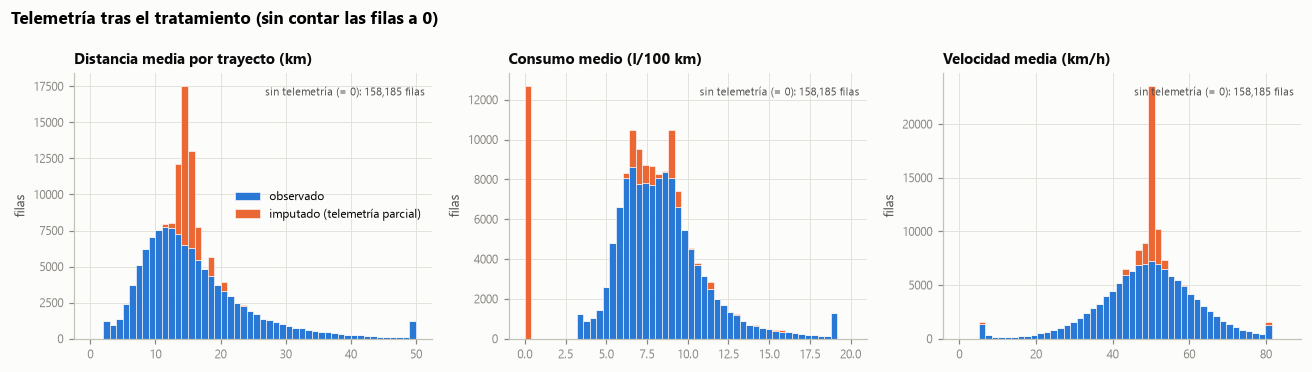

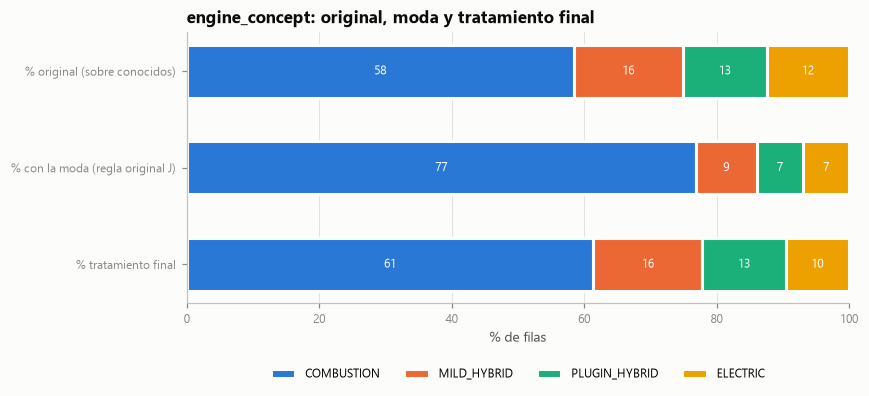

In [24]:
ec_cmp = pd.concat([
    df.engine_concept.value_counts(normalize=True).mul(100).rename("% original (sobre conocidos)"),
    df.engine_concept.fillna(ec_mode).value_counts(normalize=True).mul(100).rename("% con la moda (regla original J)"),
    clean.engine_concept.value_counts(normalize=True).mul(100).rename("% tratamiento final"),
], axis=1).fillna(0)
md("10.2 engine_concept: original, moda y tratamiento final", ec_cmp, floatfmt=".1f")
md("10.3 Origen del valor final de engine_concept", clean.engine_concept_source.value_counts().rename("filas"))
fb = lambda s: s.str.replace("PETROL_PLUS", "PETROL").str.replace(r"^(DIESEL|PETROL),ELECTRIC$", "PHEV", regex=True)
md("10.4 fuel_type (agrupado): original frente a tratamiento final", pd.concat([
    fb(df.fuel_type.dropna()).value_counts(normalize=True).mul(100).rename("% original (sobre conocidos)"),
    fb(clean.fuel_type).value_counts(normalize=True).mul(100).rename("% tratamiento final")], axis=1), floatfmt=".1f")

imp = []
for c in ["trip_distance_average", "operating_hours_total", "fuel_consumption_average", "speed_average",
          "purchasing_power_per_inhabitant_eur", "population"]:
    b, a, h = before[c], clean[c], clean.has_telemetry if c in TELEMETRY else slice(None)
    imp.append({"columna": c, "mediana observada": b.median(), "mediana final (filas con dato)": a[h].median(),
                "% filas imputadas": b.isna().mean() * 100})
md("10.5 Medianas antes y después (en telemetría, solo sobre filas con telemetría)", pd.DataFrame(imp), index=False,
   floatfmt=",.2f")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (c, lab, rg) in zip(axes, [("trip_distance_average", "Distancia media por trayecto (km)", (0, 50)),
                                    ("fuel_consumption_average", "Consumo medio (l/100 km)", (0, 20)),
                                    ("speed_average", "Velocidad media (km/h)", (0, 85))]):
    bins = np.linspace(*rg, 51)
    obs_v = before[c].dropna().clip(*rg)
    imp_v = clean.loc[clean.tel_partial & before[c].isna(), c].clip(*rg)
    ax.hist([obs_v, imp_v], bins=bins, stacked=True, color=[BLUE, CAT[1]], edgecolor=SURFACE, linewidth=0.4,
            label=["observado", "imputado (telemetría parcial)"])
    ax.set_title(lab, fontsize=9.5)
    ax.set_ylabel("filas")
    ax.text(0.98, 0.95, f"sin telemetría (= 0): {(~clean.has_telemetry).sum():,} filas", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color=INK2)
axes[0].legend(loc="center right")
fig.suptitle("Telemetría tras el tratamiento (sin contar las filas a 0)", x=0.01, ha="left", fontsize=11, fontweight="bold")
save(fig, "fig17_impacto_relleno_telemetria.png")

fig, ax = plt.subplots(figsize=(8, 3.8))
order = ["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC"]
plot = ec_cmp.T[order]
left = np.zeros(len(plot))
for i, col in enumerate(order):
    ax.barh(plot.index, plot[col], left=left, height=0.55, color=CAT[i], edgecolor=SURFACE, linewidth=2, label=col)
    for j, v in enumerate(plot[col].values):
        if v > 4:
            ax.text(left[j] + v / 2, j, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white")
    left += plot[col].values
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.set_xlabel("% de filas")
ax.set_title("engine_concept: original, moda y tratamiento final")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
save(fig, "fig18_engine_moda_vs_reglas.png")

### 10.3 Datos tratados y vista por cliente

Se eliminan A (índice) y H (`model_class`). `client_id` y `vehicle_id` (B, C) son ruido para el modelo, pero se
conservan **solo como claves**: sin ellas no se puede agregar por cliente.

**Vista por cliente (`clientes.csv`).** Es el punto de partida del reto 2. Además de los atributos propios del
cliente, resume su flota de vehículos. La "cartera" del cliente son sus **vehículos actuales**; si no tiene
ninguno (ex-clientes), se usan todas sus relaciones. Incluye:

- **Relación con la marca:** antigüedad como cliente, vehículos actuales, vehículos distintos, relaciones históricas, meses desde la última matriculación, leasing, rol.
- **Gama de la flota:** segmento comercial (compacto, medio, SUV, lujo, deportivo, furgoneta), AMG, 4MATIC y familia de modelo principal. La gama se recupera de `model_series`, porque `model_class` se eliminó.
- **Energía:** porcentaje de BEV, PHEV, microhíbrido, combustión y diésel.
- **Mantenimiento:** visitas en garantía totales y por vehículo, y antigüedad media y mínima de la flota.
- **Uso:** telemetría media calculada **solo con las relaciones que tienen datos** (0 + `has_telemetry = False` si no hay ninguna).
- **Zona:** poder adquisitivo por habitante y por hogar, y población.

In [25]:
clean.to_csv(PROC / "relaciones_limpio.csv", index=False)

# Gama comercial a partir de la serie (model_class se recupera solo como lookup de la serie)
NEW_SERIES = {"540": "GLC-Class", "244": "GLB-Class", "248": "GLB-Class", "178": "CLA-Class", "520": "C-Class",
              "449": "V-Class / Vito"}
series_class = df.dropna(subset=["model_class"]).groupby("model_series").model_class.first().to_dict() | NEW_SERIES
FAMILY = {
    "A-Class": "A", "A-Class/CLA-Class": "A", "B-Class": "B/GLA/GLB", "B-/GLA-/GLB-Class": "B/GLA/GLB",
    "GLA-Class": "B/GLA/GLB", "GLB-Class": "B/GLA/GLB", "CLA-Class": "CLA", "C-Class": "C", "CLE-Class": "CLE/E Coupe",
    "E-Class": "E", "E-Class Coupé/Cabriolet": "CLE/E Coupe", "CLS-Class": "CLS", "CLK-Class": "CLE/E Coupe",
    "S-Class": "S/Maybach", "S-Class Coupé/Cabriolet": "S/Maybach", "Maybach": "S/Maybach", "CL-Class": "S/Maybach",
    "GLC-Class": "GLC", "GLE-/GLS-Class": "GLE/GLS", "GLE-Class": "GLE/GLS", "M-/GL-/GLE-/GLS-Class": "GLE/GLS",
    "M-/GL-Class": "GLE/GLS", "M-Class": "GLE/GLS", "R-Class": "GLE/GLS", "G-Class": "G",
    "EQA-/EQB-Class": "EQA/EQB", "EQC-Class": "EQC", "EQE-Class": "EQE/EQS", "EQS-Class": "EQE/EQS",
    "SL-Class": "Deportivo", "SLK-/SLC-Class": "Deportivo", "SLK-Class": "Deportivo", "AMG GT": "Deportivo",
    "AMG GT 4-Door": "Deportivo", "AMG ONE": "Deportivo", "SLS AMG": "Deportivo", "SLR McLaren": "Deportivo",
    "V-Class / Vito": "Van", "Viano/Vito": "Van", "Sprinter": "Van", "Citan": "Van", "X-Class": "Van",
    "fortwo / forfour": "smart",
}
SEGMENT = {"A": "compacto", "B/GLA/GLB": "compacto", "CLA": "compacto", "smart": "compacto", "EQA/EQB": "compacto",
           "C": "medio", "E": "medio", "CLE/E Coupe": "medio", "CLS": "medio",
           "GLC": "suv", "GLE/GLS": "suv", "G": "suv", "EQC": "suv",
           "S/Maybach": "lujo", "EQE/EQS": "lujo", "Deportivo": "deportivo", "Van": "furgoneta"}
v = clean.assign(
    family=clean.model_series.map(series_class).map(FAMILY).fillna("Otros"),
    is_amg=clean.vehicle_type.str.upper().str.startswith("AMG"),
    is_4matic=clean.vehicle_type.str.contains("4MATIC", case=False),
    is_diesel=clean.fuel_type.str.startswith("DIESEL"))
v["segment"] = v.family.map(SEGMENT).fillna("medio")
v.loc[v.product_group == "T", "segment"] = "furgoneta"

# Cartera = vehículos actuales; si el cliente no tiene ninguno, todas sus relaciones
has_cur = v.groupby("client_id").is_current_vehicle.transform("any")
port = v[v.is_current_vehicle | ~has_cur]
gp, gc = port.groupby("client_id"), v.groupby("client_id")

clients = v.drop_duplicates("client_id").set_index("client_id")[
    ["age_range", "gender_derived", "country_code", "months_as_mb_customer", "months_is_36_spike",
     "currently_connected_vehicles", "finance_leasing_status", *CONSENTS, "purchasing_power_per_inhabitant_eur",
     "purchasing_power_per_household_eur", "population", "socio_imputed", "zip_imputed"]]
# Agregaciones vectorizadas (dummies + medias por grupo) para que sea rápido con 173.000 clientes
clients["n_relaciones"] = gc.size()
clients["n_vehiculos_distintos"] = gc.vehicle_id.nunique()
clients["n_relaciones_historicas"] = clients.n_relaciones - gc.is_current_vehicle.sum()
clients["tiene_vehiculo_actual"] = gc.is_current_vehicle.any()
clients["is_b2b"] = (v.role_type == "B2B").groupby(v.client_id).any()
clients["share_owner"] = (v.role == "OWNER").groupby(v.client_id).mean()
clients["rol_principal"] = port.groupby(["client_id", "role"]).size().reset_index().sort_values(0).drop_duplicates(
    "client_id", keep="last").set_index("client_id").role
clients["meses_desde_ultima_matriculacion"] = gc.vehicle_age_years.min() * 12
clients["edad_vehiculo_media"] = gp.vehicle_age_years.mean()
clients["edad_vehiculo_min"] = gp.vehicle_age_years.min()
clients["visitas_taller_total"] = gc.workshop_visits_warranty_goodwill.sum()
clients["visitas_por_vehiculo"] = clients.visitas_taller_total / clients.n_vehiculos_distintos
seg_share = pd.get_dummies(port.segment).groupby(port.client_id).mean()
for seg in ["compacto", "medio", "suv", "lujo", "deportivo", "furgoneta"]:
    clients[f"share_{seg}"] = seg_share[seg] if seg in seg_share else 0.0
clients["familia_principal"] = port.groupby(["client_id", "family"]).size().reset_index().sort_values(0).drop_duplicates(
    "client_id", keep="last").set_index("client_id").family
clients["share_amg"] = gp.is_amg.mean()
clients["share_4matic"] = gp.is_4matic.mean()
eng_share = pd.get_dummies(port.engine_concept).groupby(port.client_id).mean()
for ec, name in [("ELECTRIC", "bev"), ("PLUGIN_HYBRID", "phev"), ("MILD_HYBRID", "mhev"), ("COMBUSTION", "combustion")]:
    clients[f"share_{name}"] = eng_share[ec]
clients["share_electrificado"] = clients.share_bev + clients.share_phev
clients["share_diesel"] = gp.is_diesel.mean()
clients["has_telemetry"] = gc.has_telemetry.any()
tel_rel = v[v.has_telemetry].groupby("client_id")
for c in ["trip_distance_average", "operating_hours_total", "fuel_consumption_average", "speed_average",
          "trip_distance_all_counter"]:
    clients[c] = tel_rel[c].mean().reindex(clients.index).fillna(0.0)
clients["engine_imputed_share"] = gp.engine_imputed.mean()
clients.to_csv(PROC / "clientes.csv")
md("10.6 Vista agregada por cliente (data/processed/clientes.csv)", clients.describe(include="all").T
   .drop(columns=["top", "freq"], errors="ignore"), floatfmt=",.2f")
assert clients.notna().all().all(), "La vista por cliente tiene nulos"

(OUT / "resultados.md").write_text("# Resultados del EDA (generado por eda/EDA_reto1.ipynb)\n" + "\n".join(_md), encoding="utf-8")
print(f"OK -> {len(clean):,} filas tratadas ({clean.shape[1]} columnas), {len(clients):,} clientes")


### 10.6 Vista agregada por cliente (data/processed/clientes.csv)

|                                     |      count |   unique |       mean |       std |       min |       25% |        50% |        75% |        max |
|:------------------------------------|-----------:|---------:|-----------:|----------:|----------:|----------:|-----------:|-----------:|-----------:|
| age_range                           | 173,456.00 |     6.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| gender_derived                      | 173,456.00 |     3.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| country_code                        | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| months_as_mb_customer               | 173,456.00 |   nan    |      33.90 |     20.73 |      0.00 |     18.00 |      36.00 |      47.00 |     120.00 |
| months_is_36_spike                  | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| currently_connected_vehicles        | 173,456.00 |   nan    |       1.04 |      0.88 |      0.00 |      1.00 |       1.00 |       1.00 |      21.00 |
| finance_leasing_status              | 173,456.00 |     4.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| consent_phone_communication_channel | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| consent_epost_communication_channel | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| consent_post_communication_channel  | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| purchasing_power_per_inhabitant_eur | 173,456.00 |   nan    |  46,893.74 | 17,276.80 | 19,701.53 | 31,940.06 |  46,636.14 |  54,450.82 | 148,353.74 |
| purchasing_power_per_household_eur  | 173,456.00 |   nan    | 105,654.47 | 41,831.31 | 45,087.34 | 72,163.79 | 102,966.68 | 123,066.22 | 342,497.95 |
| population                          | 173,456.00 |   nan    |  20,351.39 | 37,662.54 |     25.00 |  3,114.00 |   7,354.00 |  18,605.00 | 220,794.00 |
| socio_imputed                       | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| zip_imputed                         | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| n_relaciones                        | 173,456.00 |   nan    |       1.75 |      5.51 |      1.00 |      1.00 |       1.00 |       2.00 |     561.00 |
| n_vehiculos_distintos               | 173,456.00 |   nan    |       1.75 |      5.51 |      1.00 |      1.00 |       1.00 |       2.00 |     561.00 |
| n_relaciones_historicas             | 173,456.00 |   nan    |       0.71 |      5.22 |      0.00 |      0.00 |       0.00 |       1.00 |     547.00 |
| tiene_vehiculo_actual               | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| is_b2b                              | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| share_owner                         | 173,456.00 |   nan    |       0.88 |      0.30 |      0.00 |      1.00 |       1.00 |       1.00 |       1.00 |
| rol_principal                       | 173,456.00 |     5.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| meses_desde_ultima_matriculacion    | 173,456.00 |   nan    |      54.96 |     36.32 |      0.43 |     25.76 |      49.74 |      79.41 |     477.01 |
| edad_vehiculo_media                 | 173,456.00 |   nan    |       4.83 |      3.02 |      0.04 |      2.44 |       4.50 |       6.83 |      39.75 |
| edad_vehiculo_min                   | 173,456.00 |   nan    |       4.65 |      3.05 |      0.04 |      2.21 |       4.24 |       6.69 |      39.75 |
| visitas_taller_total                | 173,456.00 |   nan    |       3.06 |      4.70 |      0.00 |      0.00 |       2.00 |       4.00 |     206.00 |
| visitas_por_vehiculo                | 173,456.00 |   nan    |       2.09 |      2.35 |      0.00 |      0.00 |       1.50 |       3.00 |      36.33 |
| share_compacto                      | 173,456.00 |   nan    |       0.36 |      0.47 |      0.00 |      0.00 |       0.00 |       1.00 |       1.00 |
| share_medio                         | 173,456.00 |   nan    |       0.21 |      0.40 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_suv                           | 173,456.00 |   nan    |       0.27 |      0.43 |      0.00 |      0.00 |       0.00 |       1.00 |       1.00 |
| share_lujo                          | 173,456.00 |   nan    |       0.04 |      0.18 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_deportivo                     | 173,456.00 |   nan    |       0.01 |      0.10 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_furgoneta                     | 173,456.00 |   nan    |       0.11 |      0.30 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| familia_principal                   | 173,456.00 |    17.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| share_amg                           | 173,456.00 |   nan    |       0.13 |      0.33 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_4matic                        | 173,456.00 |   nan    |       0.61 |      0.47 |      0.00 |      0.00 |       1.00 |       1.00 |       1.00 |
| share_bev                           | 173,456.00 |   nan    |       0.10 |      0.29 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_phev                          | 173,456.00 |   nan    |       0.14 |      0.34 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_mhev                          | 173,456.00 |   nan    |       0.18 |      0.38 |      0.00 |      0.00 |       0.00 |       0.00 |       1.00 |
| share_combustion                    | 173,456.00 |   nan    |       0.58 |      0.48 |      0.00 |      0.00 |       1.00 |       1.00 |       1.00 |
| share_electrificado                 | 173,456.00 |   nan    |       0.24 |      0.42 |      0.00 |      0.00 |       0.00 |       0.50 |       1.00 |
| share_diesel                        | 173,456.00 |   nan    |       0.44 |      0.49 |      0.00 |      0.00 |       0.00 |       1.00 |       1.00 |
| has_telemetry                       | 173,456.00 |     2.00 |     nan    |    nan    |    nan    |    nan    |     nan    |     nan    |     nan    |
| trip_distance_average               | 173,456.00 |   nan    |       9.32 |      9.51 |      0.00 |      0.00 |       9.58 |      15.22 |      49.39 |
| operating_hours_total               | 173,456.00 |   nan    |     369.43 |    532.59 |      0.00 |      0.00 |     142.06 |     530.16 |   3,394.76 |
| fuel_consumption_average            | 173,456.00 |   nan    |       4.50 |      4.47 |      0.00 |      0.00 |       5.46 |       8.14 |      19.00 |
| speed_average                       | 173,456.00 |   nan    |      29.32 |     25.71 |      0.00 |      0.00 |      39.39 |      50.45 |      80.50 |
| trip_distance_all_counter           | 173,456.00 |   nan    |   1,491.26 |  2,079.87 |      0.00 |      0.00 |     745.00 |   2,262.00 |  54,034.00 |
| engine_imputed_share                | 173,456.00 |   nan    |       0.43 |      0.48 |      0.00 |      0.00 |       0.00 |       1.00 |       1.00 |


OK -> 302,850 filas tratadas (47 columnas), 173,456 clientes


## 11. Conclusiones

**Principales características de los clientes:** base B2C (99,4 %), madura (61 % con 45 años o más) y mayoritariamente
masculina, concentrada en Suiza (66 %) y con un único vehículo conectado (81 %). El 71 % nunca ha usado leasing y el
81 % acepta todos los canales de contacto. La flota está dominada por SUV y compactos premium (GLC, C, A, B/GLA/GLB),
con una electrificación que se acelera: los BEV son el 37,5 % de las matriculaciones de 2026.

**Calidad de datos:** el grano es cliente–vehículo; hay telemetría estructuralmente ausente (52 %), motorización
incompleta (44–59 %), columnas redundantes, un pico artificial en 36 meses como cliente, una taxonomía de modelo solapada
y CP erróneos. Todo queda tratado, sin nulos y con las comprobaciones de coherencia a 0.

El resumen breve del reto está en `eda/Resumen_reto1.md`.